# Predicting Residential Property Sale Prices in New York City (2025)
**Module:** 6COSC017C Machine Learning and Data Analytics — CW1

**Business question:** Can we predict the sale price of a residential property in New York City from its physical characteristics, location and sale timing — and which factors drive price the most?

**Dataset:** NYC Department of Finance — Annualized Property Sales, calendar year 2025 (five borough files).
Source: https://www.nyc.gov/site/finance/property/property-annualized-sales-update.page (public NYC government data).

**Notebook structure**
1. Load data (combine 5 borough files)
2. First look at the data
3. Exploratory Data Analysis
4. Data preparation
5. Model training *(next)*
6. Model evaluation *(next)*

## 0. Setup — libraries

In [1]:
# Core data handling
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Statistics (trimmed mean, Q-Q plots)
from scipy import stats

# Display settings so wide tables are readable
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

# Fixed random seed so every result in this notebook is reproducible
RANDOM_STATE = 42

## 1. Load data

The Department of Finance publishes one Excel file per borough. Each file has **6 title/note lines** at the top, then the column headers on line 7, followed by one empty row.
We therefore:
1. read each file with `header=6` (0-based row index of the header line),
2. drop fully empty rows,
3. add a `borough_name` column so we keep track of where each row came from,
4. stack (concatenate) the five files into one DataFrame — they share exactly the same 21 columns, so a vertical concatenation is the correct way to combine them.

In [2]:
# Raw data lives in the data/ folder next to notebooks/
from pathlib import Path
DATA_DIR = Path("../data")

# File name -> readable borough name
BOROUGH_FILES = {
    "2025_manhattan.xlsx":     "Manhattan",
    "2025_bronx.xlsx":         "Bronx",
    "2025_brooklyn.xlsx":      "Brooklyn",
    "2025_queens.xlsx":        "Queens",
    "2025_staten_island.xlsx": "Staten Island",
}

frames = []
for file_name, borough in BOROUGH_FILES.items():
    df_b = pd.read_excel(DATA_DIR / file_name, header=6)   # header is on the 7th line
    df_b = df_b.dropna(how="all")               # remove empty spacer rows
    df_b["borough_name"] = borough              # remember the source file
    frames.append(df_b)
    print(f"{borough:<14} {len(df_b):>7,} rows")

df_raw = pd.concat(frames, ignore_index=True)
print(f"\nCombined dataset: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")

Manhattan       19,724 rows


Bronx            6,818 rows


Brooklyn        23,472 rows


Queens          27,258 rows


Staten Island    7,796 rows

Combined dataset: 85,068 rows x 22 columns


### 1.1 Clean column names
The original headers contain line breaks, double spaces and capital letters (e.g. `'GROSS \nSQUARE FEET'`). We convert them to `snake_case` so they are easy to use in code.

In [3]:
def clean_col(name: str) -> str:
    name = " ".join(str(name).split())          # remove line breaks / extra spaces
    return name.lower().replace("-", "").replace(" ", "_")

df_raw.columns = [clean_col(c) for c in df_raw.columns]
df_raw.columns.tolist()

['borough',
 'neighborhood',
 'building_class_category',
 'tax_class_at_present',
 'block',
 'lot',
 'easement',
 'building_class_at_present',
 'address',
 'apartment_number',
 'zip_code',
 'residential_units',
 'commercial_units',
 'total_units',
 'land_square_feet',
 'gross_square_feet',
 'year_built',
 'tax_class_at_time_of_sale',
 'building_class_at_time_of_sale',
 'sale_price',
 'sale_date',
 'borough_name']

### 1.2 Sanity checks after loading
We confirm that every borough loaded, that the sale dates cover the full 2025 calendar year, and that the combination produced no duplicate rows.

In [4]:
print("Rows per borough:")
print(df_raw["borough_name"].value_counts(), "\n")

print("Sale date range:", df_raw["sale_date"].min().date(), "to", df_raw["sale_date"].max().date())
print("Exact duplicate rows:", df_raw.duplicated().sum())

Rows per borough:
borough_name
Queens           27258
Brooklyn         23472
Manhattan        19724
Staten Island     7796
Bronx             6818
Name: count, dtype: int64 

Sale date range: 2025-01-01 to 2025-12-31
Exact duplicate rows: 0


## 2. First look at the data

In [5]:
df_raw.head()

,borough,neighborhood,building_class_category,tax_class_at_present,block,lot,easement,building_class_at_present,address,apartment_number,zip_code,residential_units,commercial_units,total_units,land_square_feet,gross_square_feet,year_built,tax_class_at_time_of_sale,building_class_at_time_of_sale,sale_price,sale_date,borough_name
0,1.00,ALPHABET CITY,01 ONE FAMILY DWELLINGS,1,376.00,43.00,NaN,S1,743 EAST 6 STREET,NaN,"10,009.00",1.00,1.00,2.00,"2,090.00","3,680.00","1,940.00",1.00,S1,0.00,2025-01-23,Manhattan
1,1.00,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2B,372.00,9.00,NaN,C7,272 EAST 3 STREET,NaN,"10,009.00",8.00,1.00,9.00,"2,021.00","7,129.00","1,900.00",2.00,C7,0.00,2025-12-15,Manhattan
2,1.00,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2B,372.00,19.00,NaN,C7,"292 EAST 3 STREET, 4B",NaN,"10,009.00",9.00,1.00,10.00,"2,401.00","6,920.00","1,920.00",2.00,C7,0.00,2025-02-07,Manhattan
3,1.00,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2,376.00,41.00,NaN,C6,"745 EAST 6TH STREET, 1B",NaN,"10,009.00",28.00,0.00,28.00,"4,542.00","18,254.00","1,900.00",2.00,C4,"540,000.00",2025-12-17,Manhattan
4,1.00,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2,385.00,38.00,NaN,C6,"21-23 AVENUE C, 5B",NaN,"10,009.00",20.00,2.00,22.00,"3,315.00","17,160.00","1,900.00",2.00,C4,0.00,2025-11-11,Manhattan


### 2.1 Data types
`info()` shows each column's type and how many non-missing values it has. This tells us which columns are numeric (usable directly in models) and which are text/categorical (need encoding later).

In [6]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85068 entries, 0 to 85067
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   borough                         85068 non-null  float64       
 1   neighborhood                    85068 non-null  object        
 2   building_class_category         85068 non-null  object        
 3   tax_class_at_present            85068 non-null  object        
 4   block                           85068 non-null  float64       
 5   lot                             85068 non-null  float64       
 6   easement                        0 non-null      float64       
 7   building_class_at_present       85068 non-null  object        
 8   address                         85068 non-null  object        
 9   apartment_number                20679 non-null  object        
 10  zip_code                        85049 non-null  float64       
 11  re

### 2.2 Missing values
Missing values must be identified before modelling, because most scikit-learn models cannot handle them. We show the count and percentage per column.

In [7]:
missing = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_pct":   (df_raw.isna().mean() * 100).round(1),
}).sort_values("missing_pct", ascending=False)
missing[missing["missing_count"] > 0]

,missing_count,missing_pct
easement,85068,100.00
apartment_number,64389,75.70
gross_square_feet,38358,45.10
land_square_feet,38360,45.10
commercial_units,35207,41.40
residential_units,20663,24.30
total_units,17510,20.60
year_built,5562,6.50
zip_code,19,0.00


**Observations**
- `easement` is 100% empty → it carries no information and will be dropped.
- `apartment_number` is mostly empty because it only applies to individual apartment units.
- `land_square_feet` and `gross_square_feet` are missing for many rows. In this dataset, co-op and condo sales are recorded **per apartment unit**, so building size is not recorded for them. This drives our scope decision in the Data Preparation section.

### 2.3 The target variable: `sale_price`
Not every record is a real market sale. Transfers between family members, or deeds transferred for legal reasons, are recorded with a price of **$0** or a token amount. These are not market prices and would mislead a price model.

In [8]:
price = df_raw["sale_price"]
print(f"Sales recorded at $0:        {(price == 0).sum():>7,}")
print(f"Sales below $10,000:         {(price < 10_000).sum():>7,}")
print(f"Sales of $10,000 or more:    {(price >= 10_000).sum():>7,}")
print()
price[price >= 10_000].describe()

Sales recorded at $0:         29,608
Sales below $10,000:          31,436
Sales of $10,000 or more:     53,632



count          53,632.00
mean        3,265,885.50
std        18,620,058.12
min            10,000.00
25%           560,000.00
50%           885,000.00
75%         1,550,000.00
max     1,080,000,000.00
Name: sale_price, dtype: float64

**Observation:** among real sales, the median price is far below the mean and the maximum is over $1 billion → the target is **heavily right-skewed**. We will look at this in the EDA and consider a log transformation.

### 2.4 Building class categories
The dataset mixes very different property types (houses, apartments, offices, garages, vacant land). Predicting one price for all of them would not be meaningful, so we look at what is there.

In [9]:
df_raw["building_class_category"].value_counts().head(15)

building_class_category
01 ONE FAMILY DWELLINGS              18578
02 TWO FAMILY DWELLINGS              15732
10 COOPS - ELEVATOR APARTMENTS       13620
13 CONDOS - ELEVATOR APARTMENTS      13464
03 THREE FAMILY DWELLINGS             4522
07 RENTALS - WALKUP APARTMENTS        2880
09 COOPS - WALKUP APARTMENTS          2448
04 TAX CLASS 1 CONDOS                 1620
15 CONDOS - 2-10 UNIT RESIDENTIAL     1507
44 CONDO PARKING                      1434
17 CONDO COOPS                        1304
12 CONDOS - WALKUP APARTMENTS         1000
05 TAX CLASS 1 VACANT LAND             965
22 STORE BUILDINGS                     825
29 COMMERCIAL GARAGES                  598
Name: count, dtype: int64

**Observation:** the three most common categories are 1-family, 2-family and 3-family homes. For these, building size, land size and year built are recorded, which makes them the best-suited group for a price-prediction model.

---
## 3. Exploratory Data Analysis (EDA)

### 3.0 Analysis population
Based on Section 2, the EDA focuses on the population the model will actually be used for:

| Filter | Reason |
|---|---|
| Building class category **01, 02, 03** (1-, 2- and 3-family homes) | Most common residential type; building size, land size and year built are recorded for them (unlike co-ops/condos, which are recorded per unit). Mixing houses with offices, garages or vacant land would make a single price model meaningless. |
| `sale_price >= $10,000` | Removes $0 and token transfers (family transfers, legal deed changes) that are not market prices. |

We keep this as a *copy* (`df_res`) so the raw data stays untouched. Remaining data-quality problems (missing sizes, impossible values, package sales) are only **identified** here and **fixed** in Section 4.

In [10]:
RESIDENTIAL_CATEGORIES = [
    "01 ONE FAMILY DWELLINGS",
    "02 TWO FAMILY DWELLINGS",
    "03 THREE FAMILY DWELLINGS",
]
MIN_MARKET_PRICE = 10_000

is_residential = df_raw["building_class_category"].isin(RESIDENTIAL_CATEGORIES)
is_market_sale = df_raw["sale_price"] >= MIN_MARKET_PRICE

df_res = df_raw[is_residential & is_market_sale].copy()

# Short labels make the charts easier to read
df_res["home_type"] = df_res["building_class_category"].map({
    "01 ONE FAMILY DWELLINGS":   "1-family",
    "02 TWO FAMILY DWELLINGS":   "2-family",
    "03 THREE FAMILY DWELLINGS": "3-family",
})

print(f"All records:                    {len(df_raw):>7,}")
print(f"1-3 family homes:               {is_residential.sum():>7,}")
print(f"1-3 family market sales (kept): {len(df_res):>7,}")
print(f"Share of 1-3 family records that are non-market transfers: "
      f"{1 - len(df_res) / is_residential.sum():.1%}")

All records:                     85,068
1-3 family homes:                38,832
1-3 family market sales (kept):  19,645
Share of 1-3 family records that are non-market transfers: 49.4%


### 3.1 Shape and variable types
Each variable is classified using the standard taxonomy: **numerical** (continuous or discrete) and **categorical** (nominal or ordinal). The type decides which statistics and plots make sense (e.g. a mean of ZIP codes is meaningless) and how the variable is encoded in Section 4.

In [11]:
print("Shape of the analysis population:", df_res.shape)

numeric_cols = ["sale_price", "gross_square_feet", "land_square_feet", "year_built",
                "residential_units", "commercial_units", "total_units"]
categorical_cols = ["borough_name", "neighborhood", "home_type", "zip_code",
                    "building_class_at_time_of_sale", "tax_class_at_time_of_sale"]

variable_types = pd.DataFrame([
    ("sale_price",                     "Numerical", "Continuous", "Target variable, in dollars"),
    ("gross_square_feet",              "Numerical", "Continuous", "Floor area of the building"),
    ("land_square_feet",               "Numerical", "Continuous", "Area of the plot"),
    ("year_built",                     "Numerical", "Discrete",   "Whole years"),
    ("residential_units",              "Numerical", "Discrete",   "Count of homes in the building"),
    ("commercial_units",               "Numerical", "Discrete",   "Count of shops/offices"),
    ("total_units",                    "Numerical", "Discrete",   "Residential + commercial"),
    ("borough_name",                   "Categorical", "Nominal",  "5 boroughs, no natural order"),
    ("neighborhood",                   "Categorical", "Nominal",  "About 230 values"),
    ("zip_code",                       "Categorical", "Nominal",  "Stored as a number, but it is a label: arithmetic on it is meaningless"),
    ("home_type",                      "Categorical", "Ordinal",  "1- < 2- < 3-family (more units)"),
    ("building_class_at_time_of_sale", "Categorical", "Nominal",  "Detailed class code, e.g. A1, B2"),
    ("tax_class_at_time_of_sale",      "Categorical", "Nominal",  "Tax class code"),
    ("sale_date",                      "Date",        "—",        "Source of time features (month, quarter)"),
], columns=["variable", "type", "subtype", "note"])
variable_types

Shape of the analysis population: (19645, 23)


,variable,type,subtype,note
0,sale_price,Numerical,Continuous,"Target variable, in dollars"
1,gross_square_feet,Numerical,Continuous,Floor area of the building
2,land_square_feet,Numerical,Continuous,Area of the plot
3,year_built,Numerical,Discrete,Whole years
4,residential_units,Numerical,Discrete,Count of homes in the building
5,commercial_units,Numerical,Discrete,Count of shops/offices
6,total_units,Numerical,Discrete,Residential + commercial
7,borough_name,Categorical,Nominal,"5 boroughs, no natural order"
8,neighborhood,Categorical,Nominal,About 230 values
9,zip_code,Categorical,Nominal,"Stored as a number, but it is a label: arithme..."


### 3.2 Summary statistics — numeric variables
- **Central tendency:** mean, median and a 10% **trimmed mean** (the mean after removing the top and bottom 10%). The mean is sensitive to skew and outliers; the median and trimmed mean are robust to them.
- **Dispersion:** range, variance, standard deviation and the **interquartile range** (IQR = Q3 − Q1, the spread of the middle 50%). The IQR is also the basis of the outlier rule used in Section 4.
- **Shape:** skewness, interpreted with the usual rule of thumb: |skew| < 0.5 fairly symmetric, 0.5–1 moderate skew, > 1 high skew. Kurtosis shows how heavy the tails are.

This matters because models such as linear regression work best with roughly symmetric variables, and heavy tails mean a few extreme rows can dominate the fit.

In [12]:
num = df_res[numeric_cols]

def skew_label(s):
    """Rule of thumb for interpreting skewness."""
    s = abs(s)
    return "fairly symmetric" if s < 0.5 else ("moderate skew" if s <= 1 else "high skew")

summary = pd.DataFrame({
    "count":        num.count(),
    "mean":         num.mean(),
    "trimmed_mean": num.apply(lambda c: stats.trim_mean(c.dropna(), 0.10)),
    "median":       num.median(),
    "variance":     num.var(),
    "std":          num.std(),
    "min":          num.min(),
    "Q1":           num.quantile(0.25),
    "Q3":           num.quantile(0.75),
    "IQR":          num.quantile(0.75) - num.quantile(0.25),
    "max":          num.max(),
    "range":        num.max() - num.min(),
    "skewness":     num.skew(),
    "kurtosis":     num.kurt(),
})
summary["skew_interpretation"] = summary["skewness"].apply(skew_label)
summary

,count,mean,trimmed_mean,median,variance,std,min,Q1,Q3,IQR,max,range,skewness,kurtosis,skew_interpretation
sale_price,19645,"1,149,331.46","961,232.04","895,000.00","1,563,679,250,827.86","1,250,471.61","10,000.00","686,000.00","1,250,000.00","564,000.00","46,000,000.00","45,990,000.00",11.19,234.49,high skew
gross_square_feet,19569,"1,992.23","1,884.34","1,800.00","917,197.96",957.70,0.00,"1,344.00","2,400.00","1,056.00","43,504.00","43,504.00",6.32,197.23,high skew
land_square_feet,19569,"3,102.42","2,796.32","2,500.00","4,825,152.91","2,196.62",297.00,"2,000.00","4,000.00","2,000.00","88,945.00","88,648.00",9.65,225.48,high skew
year_built,19634,"1,942.35","1,939.47","1,935.00",948.63,30.80,"1,826.00","1,920.00","1,960.00",40.00,"2,025.00",199.00,0.79,-0.00,moderate skew
residential_units,19569,1.59,1.49,1.00,0.74,0.86,0.00,1.00,2.00,1.00,73.00,73.00,29.99,"2,445.64",high skew
commercial_units,19569,0.03,0.00,0.00,0.03,0.17,0.00,0.00,0.00,0.00,3.00,3.00,5.98,37.51,high skew
total_units,19569,1.62,1.52,1.00,0.78,0.89,0.00,1.00,2.00,1.00,75.00,75.00,29.61,"2,407.17",high skew


In [13]:
# Percentiles of the target give a feel for the price range of a "typical" home
df_res["sale_price"].quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).to_frame("sale_price")

,sale_price
0.01,"150,000.00"
0.05,"400,000.00"
0.25,"686,000.00"
0.50,"895,000.00"
0.75,"1,250,000.00"
0.95,"2,500,000.00"
0.99,"5,850,000.00"


**Observations**
- The **median sale price is about \$895k, but the mean is about \$1.15M**. When the mean is well above the median, a small number of very expensive homes pull the average up. The 10% trimmed mean (about \$961k) sits much closer to the median, which confirms that the gap comes from the extreme tail. With a skewness of about 11, `sale_price` falls in the **high skew** category.
- The middle 50% of homes sold between about \$686k (Q1) and \$1.25M (Q3), an IQR of about \$564k. The full range (\$10k to \$46M) is far wider than that, which again points to extreme values in both tails.
- `gross_square_feet`, `land_square_feet` and the unit counts are also **highly skewed** (skewness 6–30), with a few very large properties.
- `residential_units` has a **maximum of 73**, which is impossible for a 1–3 family home. This is a data error and will be corrected in Section 4.
- `year_built` has **moderate skew** (about 0.8). Most homes were built in the first half of the 20th century (median 1935).
- `commercial_units` is 0 for about 97% of homes, so on its own it carries very little information.

### 3.3 Summary statistics — categorical variables
For categorical variables, mean and variance do not apply; instead we look at the number of distinct values (cardinality) and the most frequent value. High cardinality affects the encoding choice in Section 4.

In [14]:
df_res[categorical_cols].astype(str).describe().T

,count,unique,top,freq
borough_name,19645,5,Queens,7918
neighborhood,19645,229,FLUSHING-NORTH,583
home_type,19645,3,1-family,10196
zip_code,19645,163,10314.0,665
building_class_at_time_of_sale,19645,18,A1,3779
tax_class_at_time_of_sale,19645,1,1.0,19645


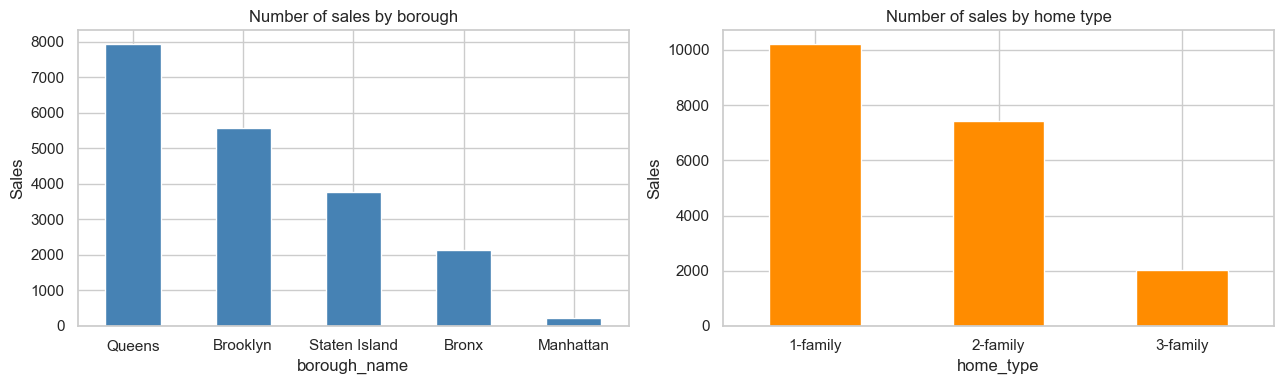

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

df_res["borough_name"].value_counts().plot.bar(ax=axes[0], color="steelblue")
axes[0].set_title("Number of sales by borough")
axes[0].set_ylabel("Sales")
axes[0].tick_params(axis="x", rotation=0)

df_res["home_type"].value_counts().sort_index().plot.bar(ax=axes[1], color="darkorange")
axes[1].set_title("Number of sales by home type")
axes[1].set_ylabel("Sales")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Observations**
- Queens and Brooklyn account for most sales; **Manhattan has only about 240 house sales**, because Manhattan housing is mostly apartments. A model will have little data to learn Manhattan prices from, so we should check its error per borough.
- `neighborhood` (about 230 values) and `zip_code` (about 160 values) have **high cardinality**. One-hot encoding all of them would create hundreds of sparse columns, so a different approach (e.g. target encoding or grouping) is considered in Section 4.
- `tax_class_at_time_of_sale` has a single value (class 1) for every row, so it carries **no information** and will be dropped.

### 3.4 Distribution of the target variable
The shape of the target decides whether we model the price directly or a transformation of it. A strongly skewed target makes squared-error models focus on the few most expensive homes.

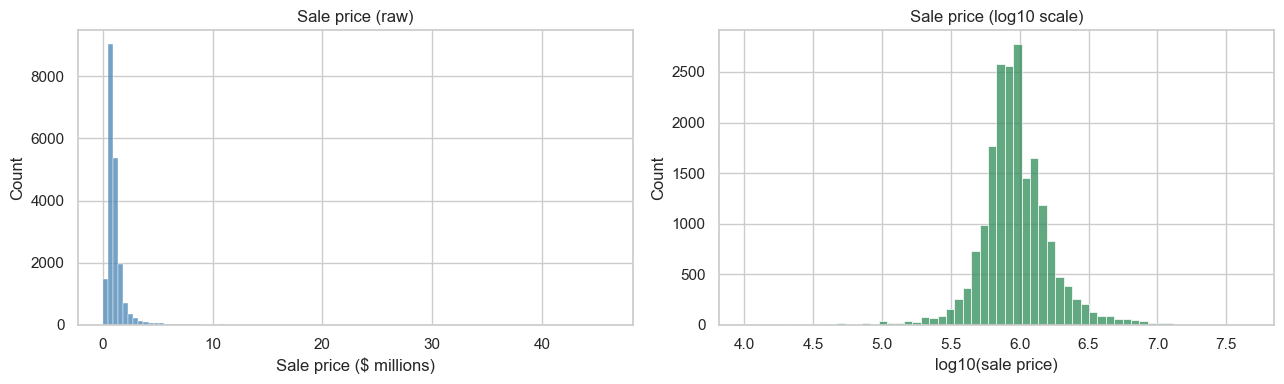

Skewness raw: 11.19   |   Skewness log: -0.27


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df_res["sale_price"] / 1e6, bins=100, ax=axes[0], color="steelblue")
axes[0].set_title("Sale price (raw)")
axes[0].set_xlabel("Sale price ($ millions)")

sns.histplot(np.log10(df_res["sale_price"]), bins=60, ax=axes[1], color="seagreen")
axes[1].set_title("Sale price (log10 scale)")
axes[1].set_xlabel("log10(sale price)")

plt.tight_layout()
plt.show()

print(f"Skewness raw: {df_res['sale_price'].skew():.2f}   |   "
      f"Skewness log: {np.log(df_res['sale_price']).skew():.2f}")

**Observations:** the raw price has a long right tail, and its skewness drops from about 11 (high skew) to about −0.3 (fairly symmetric) after a log transformation. On a log scale it becomes close to bell-shaped, with a small left tail of very low prices (likely non-arm's-length sales that passed the \$10k filter).

#### Checking normality with Q-Q plots
A histogram can hide how far a distribution is from normal. A **Q-Q (quantile-quantile) plot** compares the quantiles of the data with the quantiles of a normal distribution: if the points lie close to the straight line, the variable is approximately normal. Curving away from the line at the ends shows heavy tails or skew.

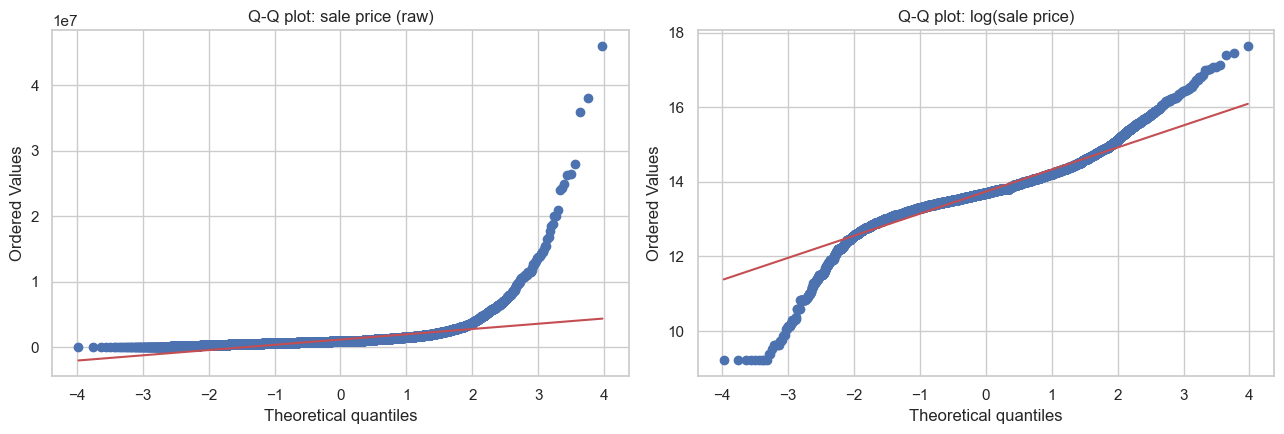

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

stats.probplot(df_res["sale_price"], dist="norm", plot=axes[0])
axes[0].set_title("Q-Q plot: sale price (raw)")

stats.probplot(np.log(df_res["sale_price"]), dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot: log(sale price)")

plt.tight_layout()
plt.show()

**Observations:** the raw price curves sharply upward at the right end, a clear sign of a heavy right tail, so it is far from normal. After the log transformation the points follow the line closely through the middle of the distribution (roughly the central 95% of sales). Both ends still deviate: the **left tail drops sharply** (the cheapest few percent of sales are far below what a normal distribution predicts) and the right tail bends upward more mildly (luxury homes). So log(price) is much closer to normal, but not perfectly normal. The very low prices are the strongest deviation and are investigated as outliers in Section 4.

**Decision:** the models will predict `log(sale_price)`. This reduces the influence of extreme prices and makes errors *relative* (a \$100k mistake matters more on a \$500k home than on a \$5M home). Predictions are converted back to dollars for evaluation.

### 3.5 Distributions of numeric features
Histograms show the typical range of each feature, its skew, and suspicious values (zeros, extremes) that need cleaning.

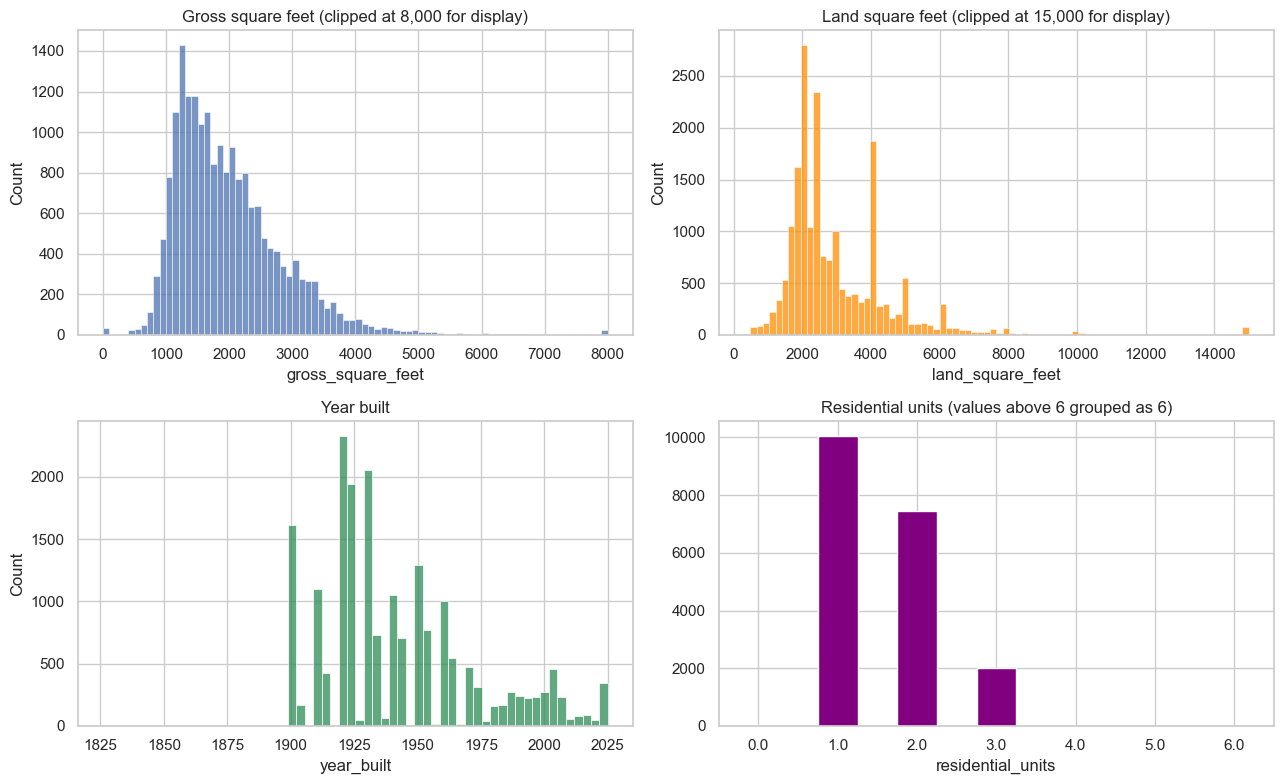

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

sns.histplot(df_res["gross_square_feet"].clip(upper=8_000), bins=80, ax=axes[0, 0])
axes[0, 0].set_title("Gross square feet (clipped at 8,000 for display)")

sns.histplot(df_res["land_square_feet"].clip(upper=15_000), bins=80, ax=axes[0, 1], color="darkorange")
axes[0, 1].set_title("Land square feet (clipped at 15,000 for display)")

sns.histplot(df_res["year_built"], bins=60, ax=axes[1, 0], color="seagreen")
axes[1, 0].set_title("Year built")

df_res["residential_units"].clip(upper=6).value_counts().sort_index().plot.bar(ax=axes[1, 1], color="purple")
axes[1, 1].set_title("Residential units (values above 6 grouped as 6)")
axes[1, 1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Observations**
- Most homes are between about 1,300 and 2,400 sq ft of floor space on plots of 2,000–4,000 sq ft. Both have long right tails. Land size has sharp spikes at 2,000, 2,500 and 4,000 sq ft, which match the standard NYC lot sizes (20×100, 25×100 and 40×100 ft).
- `year_built` shows building waves: the 1920s–1930s and the post-war boom. There are also spikes at round years (1899, 1901, 1910, 1920, 1930…), which suggests that **many build years are estimates**, not exact records.
- Some homes have **more residential units than their category allows** (more than 3), and a few have **0 gross square feet**. These are data errors for Section 4.

### 3.6 Price by borough and home type (box plots)
Box plots compare the median and spread of price across groups and show outliers. Price is plotted on a log scale so that all boroughs are visible on one chart.

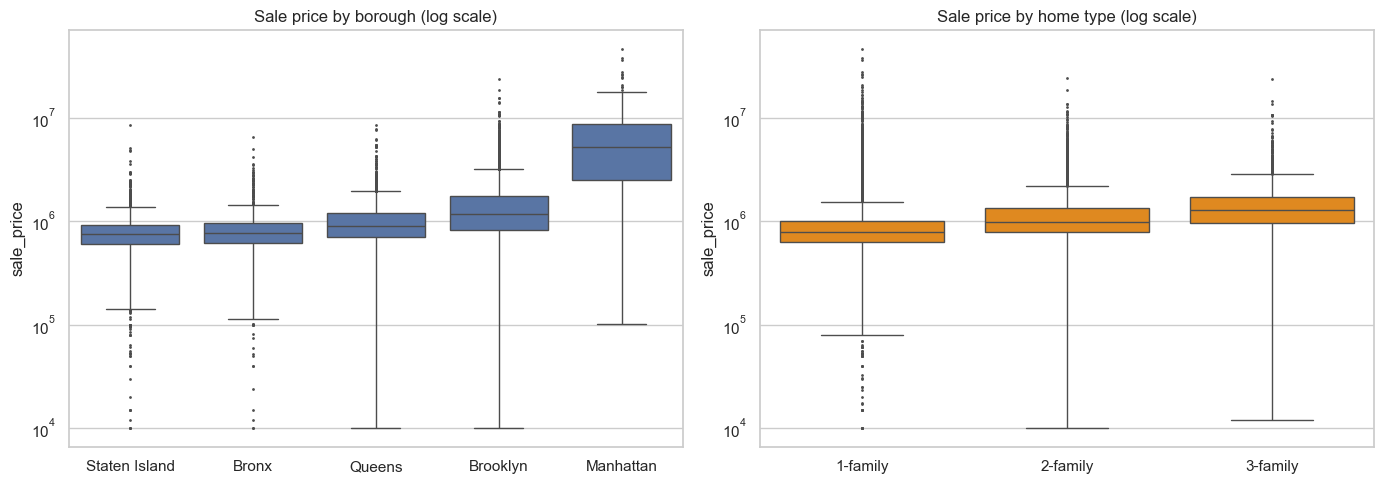

,count,mean,median,std
borough_name,,,,
Staten Island,3782,"800,318.91","745,000.00","371,564.61"
Bronx,2136,"806,913.25","760,000.00","388,347.91"
Queens,7918,"983,013.26","900,000.00","484,971.84"
Brooklyn,5572,"1,513,937.35","1,180,000.00","1,284,734.00"
Manhattan,237,"6,789,391.26","5,250,000.00","6,379,846.27"


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

borough_order = df_res.groupby("borough_name")["sale_price"].median().sort_values().index
sns.boxplot(data=df_res, x="borough_name", y="sale_price", order=borough_order,
            ax=axes[0], fliersize=1)
axes[0].set_yscale("log")
axes[0].set_title("Sale price by borough (log scale)")
axes[0].set_xlabel("")

sns.boxplot(data=df_res, x="home_type", y="sale_price", order=["1-family", "2-family", "3-family"],
            ax=axes[1], fliersize=1, color="darkorange")
axes[1].set_yscale("log")
axes[1].set_title("Sale price by home type (log scale)")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

df_res.groupby("borough_name")["sale_price"].agg(["count", "mean", "median", "std"]).loc[borough_order]

**Observations**
- **Location is the strongest driver of price.** The median Manhattan house (about \$5.25M) costs about **7× the median in the Bronx or Staten Island** (about \$750k). Brooklyn (about \$1.18M) is clearly above Queens (about \$900k).
- The spread also differs a lot by borough (Manhattan's standard deviation is about \$6.4M vs about \$0.4M in the Bronx). The model must therefore know the location, and errors will naturally be larger in expensive areas.
- Median price rises with home type (about \$780k → \$990k → \$1.27M for 1 → 3 families), because more units mean a bigger building and rental income.
- Every group has outliers on both sides. The very low ones are suspicious (e.g. a Brooklyn house under \$100k) and are handled in Section 4.

### 3.7 Building size vs price (scatter plot)
A scatter plot shows whether a relationship is linear and how strong it is. Both axes are on a log scale because both variables are right-skewed.

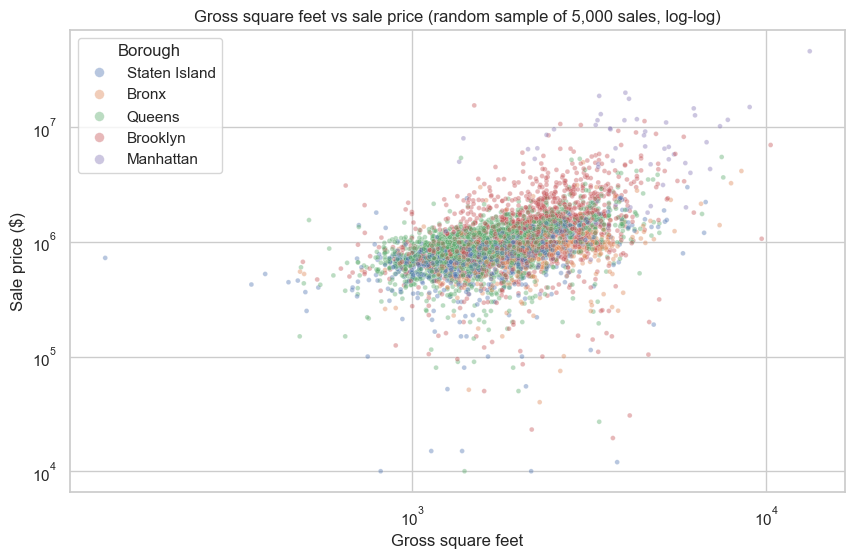

In [20]:
sample = df_res[df_res["gross_square_feet"] > 0].sample(5_000, random_state=RANDOM_STATE)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample, x="gross_square_feet", y="sale_price",
                hue="borough_name", alpha=0.4, s=12, hue_order=borough_order)
plt.xscale("log")
plt.yscale("log")
plt.title("Gross square feet vs sale price (random sample of 5,000 sales, log-log)")
plt.xlabel("Gross square feet")
plt.ylabel("Sale price ($)")
plt.legend(title="Borough", markerscale=2)
plt.show()

**Observations:** there is a clear positive relationship (bigger homes sell for more), and on the log-log scale it is roughly linear. However, the cloud is wide: homes of the **same size** can differ in price by a factor of 3–5. At a given size, **Brooklyn and Manhattan homes sit higher** than Staten Island and Bronx homes, although the boroughs overlap heavily. Size alone explains only part of the price; **size and location together** are needed. This supports models that can capture interactions (tree ensembles) and the use of log-transformed size features.

### 3.8 Correlation matrix
Correlation measures how strongly each numeric feature moves with the price and with the other features:
- **Pearson** measures *linear* relationships. We compute it on log-transformed price and sizes because the raw variables are heavily skewed.
- **Spearman** uses ranks, so it captures any *monotonic* relationship and is robust to outliers.

High correlation between two *features* (multicollinearity) is also important: it makes linear-model coefficients unstable.

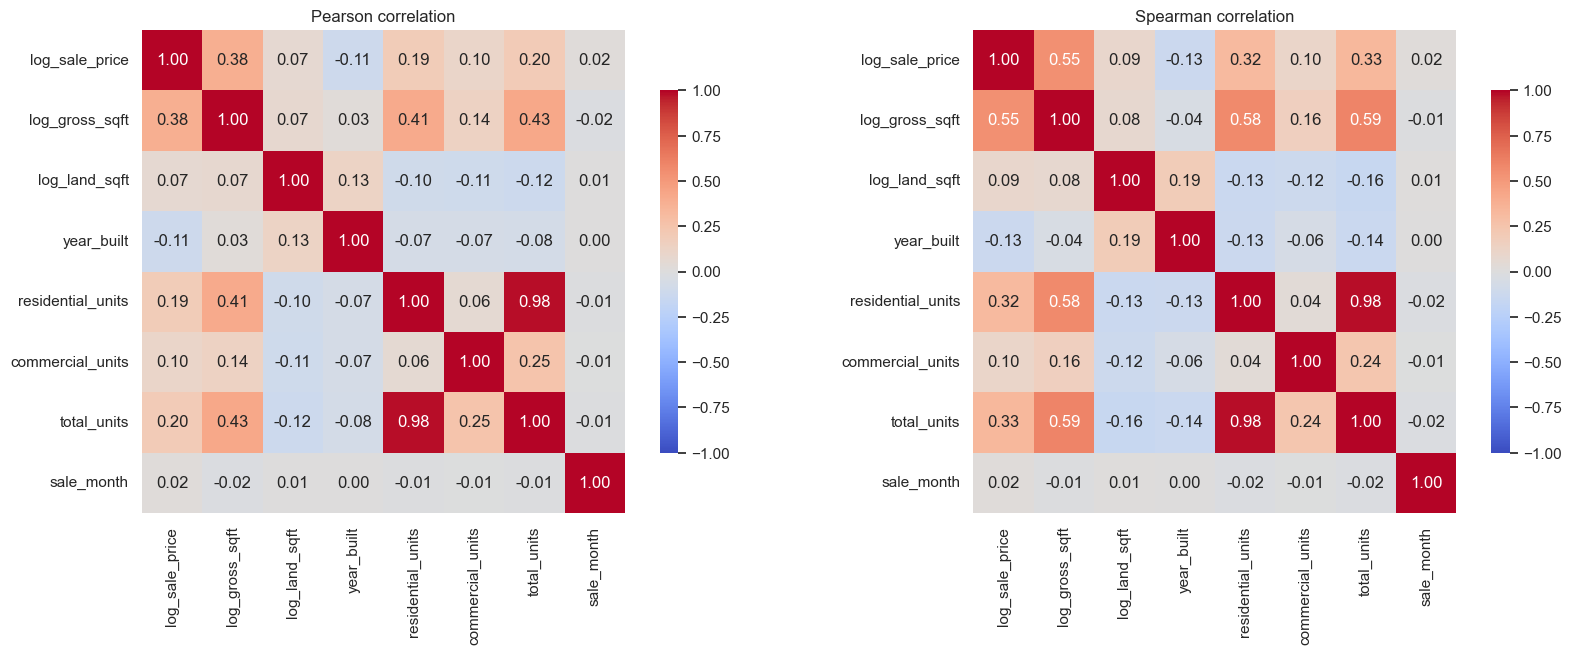

In [21]:
corr_df = pd.DataFrame({
    "log_sale_price":     np.log(df_res["sale_price"]),
    "log_gross_sqft":     np.log1p(df_res["gross_square_feet"]),
    "log_land_sqft":      np.log1p(df_res["land_square_feet"]),
    "year_built":         df_res["year_built"],
    "residential_units":  df_res["residential_units"],
    "commercial_units":   df_res["commercial_units"],
    "total_units":        df_res["total_units"],
    "sale_month":         df_res["sale_date"].dt.month,
})

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(corr_df.corr(method=method), annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.75}, ax=ax)
    ax.set_title(f"{method.capitalize()} correlation")
plt.tight_layout()
plt.show()

In [22]:
# Correlation of each feature with the (log) target, strongest first
corr_with_target = pd.DataFrame({
    "pearson":  corr_df.corr(method="pearson")["log_sale_price"],
    "spearman": corr_df.corr(method="spearman")["log_sale_price"],
}).drop("log_sale_price").sort_values("spearman", key=abs, ascending=False)
corr_with_target

,pearson,spearman
log_gross_sqft,0.38,0.55
total_units,0.20,0.33
residential_units,0.19,0.32
year_built,-0.11,-0.13
commercial_units,0.10,0.10
log_land_sqft,0.07,0.09
sale_month,0.02,0.02


**Observations**
- **Gross square feet** is the numeric feature most strongly correlated with price (Spearman about 0.55). Its Pearson correlation is lower (about 0.38) because of outliers and the non-linear, borough-dependent relationship seen in 3.7. This is why we report both measures.
- **Residential units** has a moderate positive correlation with price (about 0.3 Spearman), and it also correlates with gross square feet (more units mean a bigger building).
- **`residential_units` and `total_units` are almost perfectly correlated**, because commercial units are nearly always 0. Keeping both would add redundancy (multicollinearity) without new information, so only one is kept.
- `land_square_feet`, `year_built` and `sale_month` have **weak correlations** with price on their own. They may still help in combination with location (e.g. a large plot is worth much more in Brooklyn than in Staten Island), which tree-based models can capture.
- Overall, no single numeric feature explains price well. The box plots in 3.6 show that **location (borough/neighbourhood)** is the biggest factor, even though it does not appear in a numeric correlation matrix.

### 3.9 Sales over time
The 2025 data covers one calendar year. We check whether prices or sales volume change during the year, which tells us whether sale timing is a useful feature.

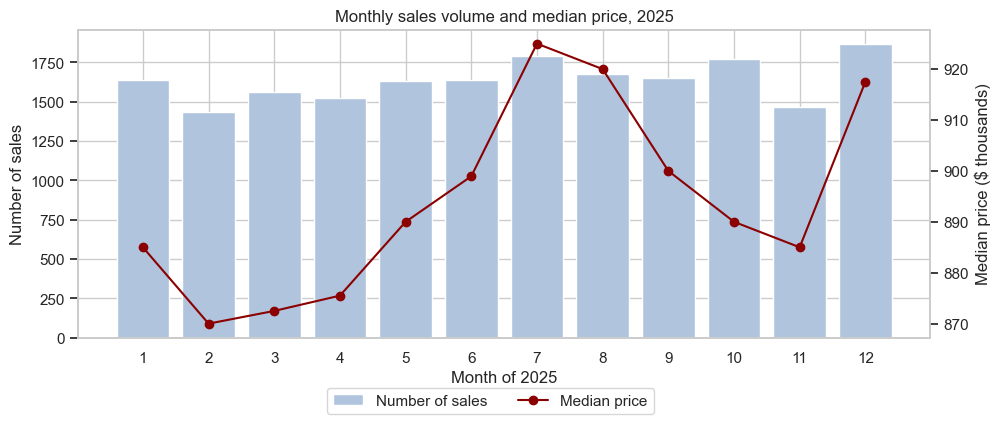

In [23]:
monthly = df_res.groupby(df_res["sale_date"].dt.month).agg(
    sales=("sale_price", "size"),
    median_price=("sale_price", "median"),
)

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(monthly.index, monthly["sales"], color="lightsteelblue", label="Number of sales")
ax1.set_xlabel("Month of 2025")
ax1.set_ylabel("Number of sales")
ax1.set_xticks(range(1, 13))

ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["median_price"] / 1e3, color="darkred", marker="o", label="Median price")
ax2.set_ylabel("Median price ($ thousands)")
ax2.grid(False)

fig.legend(loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.1))
plt.title("Monthly sales volume and median price, 2025")
plt.show()

**Observations:** sales volume is fairly steady (about 1,400–1,900 per month), and the median price moves only within a narrow band (about \$870k–\$925k), peaking in summer. The seasonal effect exists but is **small compared with location and size**. Sale month (or quarter) will be kept as a minor engineered feature.

### 3.10 Data-quality issues found during EDA
The EDA revealed several problems. We count them here; each one is handled with a justified method in **Section 4 — Data preparation**.

In [24]:
# Sales where several lots share the same block, date and price: usually one "package" deal
# recorded on several rows, each carrying the TOTAL price -> the price per row is overstated.
package_key = ["borough_name", "block", "sale_date", "sale_price"]
package_rows = df_res.duplicated(package_key, keep=False)

units_limit = df_res["home_type"].str[0].astype(int)   # 1, 2 or 3 units allowed
price_per_sqft = df_res["sale_price"] / df_res["gross_square_feet"].replace(0, np.nan)

issues = pd.Series({
    "Missing gross/land square feet":                     df_res["gross_square_feet"].isna().sum(),
    "Missing year built":                                 df_res["year_built"].isna().sum(),
    "Gross square feet recorded as 0":                    (df_res["gross_square_feet"] == 0).sum(),
    "More residential units than home type allows":       (df_res["residential_units"] > units_limit).sum(),
    "Building class changed between sale and today":      (df_res["building_class_at_present"]
                                                           != df_res["building_class_at_time_of_sale"]).sum(),
    "Rows belonging to multi-lot package sales":          package_rows.sum(),
    "Price per sq ft < $50 (implausibly cheap)":          (price_per_sqft < 50).sum(),
    "Price per sq ft > $3,000 (implausibly expensive)":   (price_per_sqft > 3_000).sum(),
    "Columns with a single value (tax class at sale)":    int(df_res["tax_class_at_time_of_sale"].nunique() == 1),
    "Columns 100% empty (easement, apartment number)":    int(df_res["easement"].isna().all())
                                                          + int(df_res["apartment_number"].isna().all()),
}, name="rows affected")
issues.to_frame()

,rows affected
Missing gross/land square feet,76
Missing year built,11
Gross square feet recorded as 0,36
More residential units than home type allows,59
Building class changed between sale and today,150
Rows belonging to multi-lot package sales,185
Price per sq ft < $50 (implausibly cheap),118
"Price per sq ft > $3,000 (implausibly expensive)",65
Columns with a single value (tax class at sale),1
"Columns 100% empty (easement, apartment number)",2


### 3.11 EDA summary
| Finding | Implication for the next steps |
|---|---|
| About half of 1–3 family records are non-market transfers (\$0 or token prices) | Restrict the model to market sales (≥ \$10k), and treat suspiciously cheap sales as outliers |
| Price is strongly right-skewed (skewness about 11) | Model `log(sale_price)`; evaluate in dollars with MAE/RMSE plus a relative metric (MAPE) |
| Location dominates price (Manhattan median about 7× the Bronx) | Location features (borough, neighbourhood/ZIP) must be included; high cardinality needs careful encoding |
| Size is the strongest numeric predictor, and the relationship differs by borough | Use log size features; prefer models that capture interactions (Random Forest, Gradient Boosting) and compare them with a linear baseline |
| `residential_units` ≈ `total_units`; `tax_class_at_time_of_sale` is constant; `easement`/`apartment_number` are empty | Drop redundant and empty columns |
| Missing sizes, zero sizes, impossible unit counts, package sales, extreme price per sq ft | Clean in Section 4 (imputation, correction or removal, each justified) |
| Very few Manhattan houses (about 240) | Report the error per borough; expect weaker accuracy for Manhattan |
| Small seasonal effect | Keep sale month/quarter as a minor feature |

---
## 4. Data preparation

Section 3 identified several data-quality problems. This section fixes them in four steps:

| Step | What | Where it happens |
|---|---|---|
| **4a** | Correct erroneous data: impossible combinations, package sales, outliers, useless columns | Whole dataset (these rules define which records are valid) |
| **4b** | Feature engineering | Whole dataset (row-by-row transformations, nothing learned from other rows) |
| **4c** | Train / validation / test split | — |
| **4d** | Missing values, scaling and encoding inside a scikit-learn `Pipeline` | **Fitted on the training set only** |

The split between "before" and "after" the train/test split is deliberate. Steps that only use a row's own values (e.g. "0 square feet is impossible") are safe on the whole dataset. Steps that **learn** something from the data (a median to fill gaps, a mean and standard deviation for scaling, the average price per neighbourhood) must be learned from the training set only. Otherwise information from the test set leaks into training and the test score overstates real-world performance (**data leakage**).

### 4a. Correcting erroneous data

We work on a copy, `df_clean`, and record how many rows each step removes so that every step can be checked.

In [25]:
df_clean = df_res.copy()

cleaning_log = [("Start: 1-3 family market sales (>= $10k)", len(df_clean))]

def log_step(description):
    """Record the row count after a cleaning step and print what changed."""
    before = cleaning_log[-1][1]
    cleaning_log.append((description, len(df_clean)))
    print(f"{description:<55} removed {before - len(df_clean):>5,}  ->  {len(df_clean):>6,} rows")

#### 4a.1 Exact duplicates
Exact duplicate rows would be counted twice and give those sales extra weight in training.

In [26]:
print("Exact duplicate rows:", df_clean.duplicated().sum())

Exact duplicate rows: 0


There are no exact duplicates, so nothing is removed. Near-duplicates (the same sale recorded on several rows) do exist and are handled in 4a.3.

#### 4a.2 Properties whose building class changed after the sale
The file header says that for sales after the tax roll date, the *descriptive* data (size, units, year built) reflect the property **today**, not at the time of sale. If a building class changed between the sale and today, the property was usually rebuilt, converted or demolished, so its size and unit figures no longer describe what was sold.

In [27]:
class_changed = df_clean["building_class_at_present"] != df_clean["building_class_at_time_of_sale"]

print(f"Sales whose building class changed after the sale: {class_changed.sum()}")
print("\nWhat they are now (first letter of current building class):")
print(df_clean.loc[class_changed, "building_class_at_present"].str[0].value_counts().rename(
    {"A": "A = 1-family", "B": "B = 2-family", "C": "C = walk-up/3-family", "V": "V = vacant land"}))

Sales whose building class changed after the sale: 150

What they are now (first letter of current building class):
building_class_at_present
B = 2-family            58
A = 1-family            37
V = vacant land         36
C = walk-up/3-family    15
O                        2
D                        1
S                        1
Name: count, dtype: int64


Many of these are now **vacant land (V)**, i.e. the house was demolished after the sale, and others changed type (e.g. 1-family → 2-family). Their recorded size and unit counts describe a different building from the one that was sold, so the features and the price do not match. They are less than 1% of the data, so we **remove** them rather than try to reconstruct the original values.

In [28]:
df_clean = df_clean[~class_changed]
log_step("Remove sales whose building class changed")

Remove sales whose building class changed               removed   150  ->  19,495 rows


#### 4a.3 Multi-lot "package" sales
Sometimes several neighbouring lots are sold together in one deal. The Department of Finance then records one row per lot, and **every row carries the total price of the whole deal**. The price on each row is therefore far higher than the value of that single lot. We detect them as rows with the same borough, tax block, sale date and sale price.

In [29]:
package_key = ["borough_name", "block", "sale_date", "sale_price"]
is_package = df_clean.duplicated(package_key, keep=False)

print(f"Rows belonging to package sales: {is_package.sum()} "
      f"(from {df_clean[is_package].groupby(package_key).ngroups} deals)")
df_clean[is_package].sort_values(package_key)[["borough_name", "block", "lot", "address",
                                               "sale_date", "sale_price"]].head(6)

Rows belonging to package sales: 181 (from 80 deals)


,borough_name,block,lot,address,sale_date,sale_price
22175,Bronx,"2,410.00",34.00,324 EAST 151 STREET,2025-12-15,"750,000.00"
22176,Bronx,"2,410.00",35.00,328 EAST 151 STREET,2025-12-15,"750,000.00"
22979,Bronx,"2,555.00",41.00,610 BEECH TERRACE,2025-01-17,"707,000.00"
22980,Bronx,"2,555.00",42.00,614 BEECH TERRACE,2025-01-17,"707,000.00"
22981,Bronx,"2,555.00",82.00,612 BEECH TERRACE,2025-01-17,"707,000.00"
22655,Bronx,"2,701.00",20.00,766 DAWSON STREET,2025-10-06,"925,000.00"


The example rows show neighbouring addresses on the same block, sold on the same day for exactly the same amount. We cannot know how the total price was divided between the lots, so these rows are **removed** (about 1% of the data). Keeping one row per deal would still pair the total price with the size of a single lot.

In [30]:
df_clean = df_clean[~is_package]
log_step("Remove multi-lot package sales")

Remove multi-lot package sales                          removed   181  ->  19,314 rows


#### 4a.4 Impossible unit counts
A 1-family home must have 1 residential unit, a 2-family home 2, and a 3-family home 3. The EDA found 59 homes with more units than their type allows (up to 73) and others with 0 units. Almost all of them were removed by the two previous steps: they were rebuilt/converted properties or package sales, whose descriptive data do not match the sale. We still check the remaining rows. When two columns contradict each other, we keep the **more reliable source**. The building class at the time of sale is assigned by the Department of Finance for the sale itself, while the unit count is descriptive data that may have been updated later, so the **building class wins** and the unit count is corrected to match it.

In [31]:
allowed_units = df_clean["home_type"].str[0].astype(int)       # "1-family" -> 1, etc.
units_wrong = df_clean["residential_units"].notna() & (df_clean["residential_units"] != allowed_units)

print(f"Rows with a unit count that contradicts the home type: {units_wrong.sum()}")
print(pd.crosstab(df_clean.loc[units_wrong, "home_type"],
                  df_clean.loc[units_wrong, "residential_units"],
                  rownames=["home type"], colnames=["recorded residential units"]))

df_clean.loc[units_wrong, "residential_units"] = allowed_units[units_wrong]
print("\nRows still contradicting after correction:",
      (df_clean["residential_units"].notna() & (df_clean["residential_units"] != allowed_units)).sum())

Rows with a unit count that contradicts the home type: 1
recorded residential units  0.00
home type                       
1-family                       1

Rows still contradicting after correction: 0


After the correction, `residential_units` is identical to the home type, so it adds no new information and is dropped in 4a.7 (together with `total_units`, which is almost the same column, as the correlation matrix showed).

#### 4a.5 Impossible building sizes
A house with **0 gross square feet** cannot exist, and floor areas below 300 sq ft (smaller than a studio apartment) are not realistic for a whole house. These values are recording errors. Removing the rows would throw away their other valid information (location, year built, price), so we set the size to **missing (NaN)** instead. The missing values are then filled in 4d together with the other gaps.

In [32]:
MIN_HOUSE_SQFT = 300
bad_size = df_clean["gross_square_feet"] < MIN_HOUSE_SQFT
print(f"Gross square feet below {MIN_HOUSE_SQFT}: {bad_size.sum()} rows -> set to NaN")
print("Values found:", sorted(df_clean.loc[bad_size, "gross_square_feet"].unique()))

df_clean.loc[bad_size, "gross_square_feet"] = np.nan

Gross square feet below 300: 1 rows -> set to NaN
Values found: [np.float64(136.0)]


#### 4a.6 Price outliers
Outliers are values that deviate strongly from the rest. Before removing any, we must check whether they are **errors / non-market sales** (remove) or **rare but real sales** (keep, because the model should learn them). We compare three detection rules:

1. **IQR rule on the raw price**: outside Q1 − 1.5·IQR … Q3 + 1.5·IQR
2. **Z-score on log(price)**: more than 3 standard deviations from the mean (assumes roughly normal data)
3. **IQR rule on log(price per square foot), computed separately for each borough**

Rule 3 judges a price *relative to what is normal for a home of that size in that borough*. A \$5M house is normal in Manhattan but extreme in the Bronx, and a big house is expected to cost more than a small one. Rules 1 and 2 ignore both, so they would flag expensive-but-normal homes.

In [33]:
log_price = np.log(df_clean["sale_price"])

# Rule 1: IQR on raw price
q1, q3 = df_clean["sale_price"].quantile([0.25, 0.75])
iqr = q3 - q1
rule1 = (df_clean["sale_price"] < q1 - 1.5 * iqr) | (df_clean["sale_price"] > q3 + 1.5 * iqr)

# Rule 2: z-score on log price
z = (log_price - log_price.mean()) / log_price.std()
rule2 = z.abs() > 3

# Rule 3: IQR on log(price per sq ft) within each borough
log_ppsf = np.log(df_clean["sale_price"] / df_clean["gross_square_feet"])
grp = log_ppsf.groupby(df_clean["borough_name"])
q1_b, q3_b = grp.transform(lambda s: s.quantile(0.25)), grp.transform(lambda s: s.quantile(0.75))
iqr_b = q3_b - q1_b
rule3_low = log_ppsf < q1_b - 1.5 * iqr_b
rule3_high = log_ppsf > q3_b + 1.5 * iqr_b

def describe_flagged(mask):
    flagged = df_clean.loc[mask]
    return pd.Series({
        "rows flagged": mask.sum(),
        "Manhattan rows flagged": (flagged["borough_name"] == "Manhattan").sum(),
        "median price of flagged": flagged["sale_price"].median(),
    })

pd.DataFrame({
    "1. IQR on raw price":            describe_flagged(rule1),
    "2. z-score on log price":        describe_flagged(rule2),
    "3. IQR log price/sqft — LOW":    describe_flagged(rule3_low),
    "3. IQR log price/sqft — HIGH":   describe_flagged(rule3_high),
}).T

,rows flagged,Manhattan rows flagged,median price of flagged
1. IQR on raw price,"1,360.00",185.00,"2,900,000.00"
2. z-score on log price,365.00,106.00,"5,850,000.00"
3. IQR log price/sqft — LOW,650.00,1.00,"250,951.00"
3. IQR log price/sqft — HIGH,136.00,0.00,"3,017,500.00"


In [34]:
# Price-per-square-foot limits implied by rule 3, per borough
ppsf_limits = pd.DataFrame({
    "lower limit ($/sqft)": np.exp(q1_b - 1.5 * iqr_b),
    "upper limit ($/sqft)": np.exp(q3_b + 1.5 * iqr_b),
    "borough": df_clean["borough_name"],
}).drop_duplicates("borough").set_index("borough").round(0)
ppsf_limits

,lower limit ($/sqft),upper limit ($/sqft)
borough,,
Manhattan,109.00,"14,058.00"
Bronx,153.00,908.00
Brooklyn,167.00,"2,076.00"
Queens,220.00,"1,389.00"
Staten Island,203.00,"1,045.00"


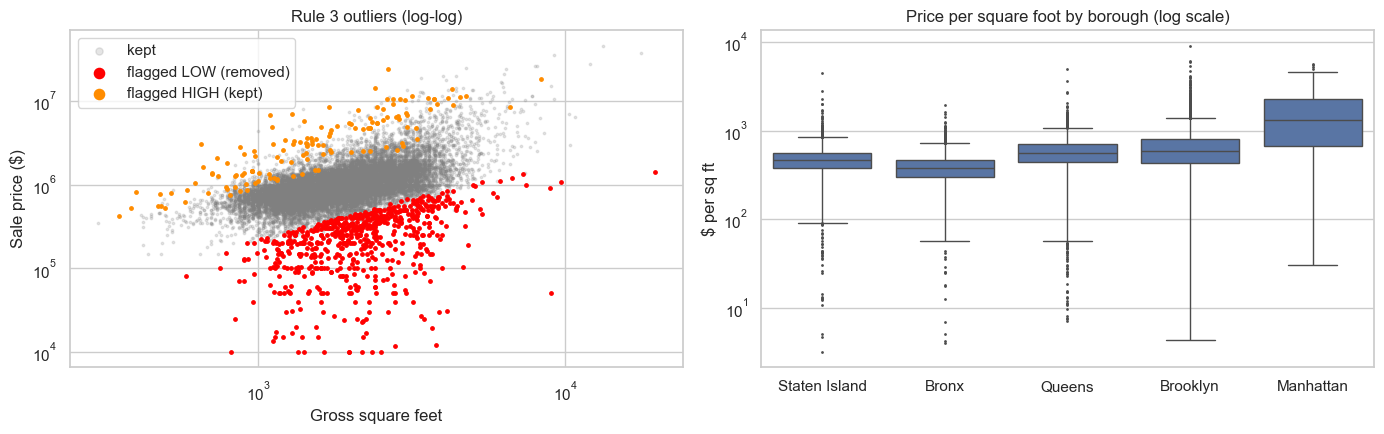

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sample_mask = df_clean["gross_square_feet"].notna()
axes[0].scatter(df_clean.loc[sample_mask & ~rule3_low & ~rule3_high, "gross_square_feet"],
                df_clean.loc[sample_mask & ~rule3_low & ~rule3_high, "sale_price"],
                s=3, alpha=0.2, color="grey", label="kept")
axes[0].scatter(df_clean.loc[rule3_low, "gross_square_feet"], df_clean.loc[rule3_low, "sale_price"],
                s=6, color="red", label="flagged LOW (removed)")
axes[0].scatter(df_clean.loc[rule3_high, "gross_square_feet"], df_clean.loc[rule3_high, "sale_price"],
                s=6, color="darkorange", label="flagged HIGH (kept)")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("Gross square feet"); axes[0].set_ylabel("Sale price ($)")
axes[0].set_title("Rule 3 outliers (log-log)")
axes[0].legend(markerscale=3)

sns.boxplot(x=df_clean["borough_name"], y=np.exp(log_ppsf), ax=axes[1], fliersize=1,
            order=["Staten Island", "Bronx", "Queens", "Brooklyn", "Manhattan"])
axes[1].set_yscale("log")
axes[1].set_title("Price per square foot by borough (log scale)")
axes[1].set_xlabel(""); axes[1].set_ylabel("$ per sq ft")

plt.tight_layout()
plt.show()

**Comparison and decision**
- **Rule 1 (IQR on raw price)** flags 1,360 homes with a median price of \$2.9M, including 185 of the 229 Manhattan houses (about 80%). These are real sales in an expensive area, so this rule would delete exactly the data the model needs for high-value homes. **Rejected.**
- **Rule 2 (z-score on log price)** also ignores size and location, and assumes normality, which the Q-Q plot showed only holds approximately. **Rejected.**
- **Rule 3, LOW side:** these homes sold for a fraction of the normal price per square foot in their borough (median price only about \$250k). The most likely explanation is a **non-market transfer** (sale to a relative, inheritance-related or distressed sale) that passed the \$10k filter. These are the same records that bend the left tail of the Q-Q plot. They do not reflect market value, which is what we want to predict, so they are **removed**.
- **Rule 3, HIGH side:** these 136 homes are concentrated in the most expensive Brooklyn neighbourhoods (Cobble Hill, Brooklyn Heights, Park Slope, Boerum Hill, Ocean Parkway), and they are smaller than average (median 1,460 sq ft vs 1,800). They look extreme only because the rule compares them with their whole **borough**, while their **neighbourhood** is far more expensive than the borough average. They are plausible real sales, so they are **kept**. Removing them would teach the model that premium neighbourhoods do not exist.

The rule needs a building size, so homes with a missing size cannot be checked and are kept. Price per square foot is used **only** to clean the data. It is derived from the target, so it is never used as a model feature (that would be target leakage).

In [36]:
df_clean = df_clean[~rule3_low]
log_step("Remove low price-per-sqft outliers (non-market)")

Remove low price-per-sqft outliers (non-market)         removed   650  ->  18,664 rows


#### 4a.7 Removing columns that are empty, constant, redundant or not usable
Each column is kept only if it can help predict the price at the time of sale **and** would be available for a new property.

In [37]:
columns_to_drop = {
    "easement":                    "100% empty",
    "apartment_number":            "100% empty for houses",
    "tax_class_at_time_of_sale":   "constant: every home is tax class 1",
    "borough":                     "numeric code duplicating borough_name",
    "building_class_category":     "replaced by the shorter home_type label",
    "residential_units":           "identical to home_type after the correction in 4a.4",
    "total_units":                 "residential + commercial units: redundant (r = 0.98 with residential_units)",
    "building_class_at_present":   "describes the property today, not at the time of sale",
    "tax_class_at_present":        "describes the property today, not at the time of sale",
    "address":                     "unique identifier, no general pattern to learn",
    "block":                       "tax-map identifier; location is captured by borough, neighbourhood and ZIP",
    "lot":                         "tax-map identifier",
}
pd.Series(columns_to_drop, name="reason").to_frame()

,reason
easement,100% empty
apartment_number,100% empty for houses
tax_class_at_time_of_sale,constant: every home is tax class 1
borough,numeric code duplicating borough_name
building_class_category,replaced by the shorter home_type label
residential_units,identical to home_type after the correction in...
total_units,residential + commercial units: redundant (r =...
building_class_at_present,"describes the property today, not at the time ..."
tax_class_at_present,"describes the property today, not at the time ..."
address,"unique identifier, no general pattern to learn"


In [38]:
df_clean = df_clean.drop(columns=list(columns_to_drop))
print("Remaining columns:", df_clean.columns.tolist())

Remaining columns: ['neighborhood', 'zip_code', 'commercial_units', 'land_square_feet', 'gross_square_feet', 'year_built', 'building_class_at_time_of_sale', 'sale_price', 'sale_date', 'borough_name', 'home_type']


#### 4a.8 Cleaning summary

In [39]:
log_df = pd.DataFrame(cleaning_log, columns=["step", "rows after step"])
log_df["rows removed"] = (-log_df["rows after step"].diff()).fillna(0).astype(int)
log_df["% of start"] = (log_df["rows after step"] / log_df["rows after step"].iloc[0] * 100).round(1)
log_df

,step,rows after step,rows removed,% of start
0,Start: 1-3 family market sales (>= $10k),19645,0,100.00
1,Remove sales whose building class changed,19495,150,99.20
2,Remove multi-lot package sales,19314,181,98.30
3,Remove low price-per-sqft outliers (non-market),18664,650,95.00


In [40]:
print(f"Final cleaned dataset: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns\n")
print("Missing values still to be handled in 4d:")
print(df_clean.isna().sum()[lambda s: s > 0])

Final cleaned dataset: 18,664 rows x 11 columns

Missing values still to be handled in 4d:
commercial_units     76
land_square_feet     76
gross_square_feet    77
year_built           10
dtype: int64


### 4b. Feature engineering
Feature engineering creates new, more informative features from the existing ones, using domain knowledge. Every feature below uses **only the values in its own row** (no statistics learned from other rows), so it is safe to create them before the train/test split without leakage.

| New feature | How it is built | Why it should help |
|---|---|---|
| `building_age` | sale year − `year_built` | "How old was the home when sold" is the quantity buyers care about; easier to interpret than a calendar year |
| `log_gross_sqft`, `log_land_sqft` | natural log of the sizes | Removes the high skew found in 3.2 and matches the roughly linear log-log relationship with price seen in 3.7. Linear models and KNN are sensitive to skewed inputs; trees are unaffected |
| `floor_area_ratio` | `gross_square_feet` / `land_square_feet` | How intensively the plot is built on. A large building on a small plot is typical of dense, expensive inner-city areas; a small house on a large plot is typical of suburban areas |
| `has_commercial` | 1 if the building has any commercial unit, else 0 | `commercial_units` is 0 for 97% of homes, so a yes/no flag captures the information more simply |
| `sale_quarter` | quarter (1–4) of `sale_date` | Captures the small seasonal effect found in 3.9 |
| `log_sale_price` | natural log of `sale_price` | The **target** the models will predict (decided in 3.4) |

In [41]:
df_feat = df_clean.copy()

# Age of the building when it was sold (clip at 0 in case a home was sold in the year it was finished)
df_feat["building_age"] = (df_feat["sale_date"].dt.year - df_feat["year_built"]).clip(lower=0)

# Log of the sizes (the sizes are all > 0 after 4a, so a plain log is safe; NaN stays NaN)
df_feat["log_gross_sqft"] = np.log(df_feat["gross_square_feet"])
df_feat["log_land_sqft"]  = np.log(df_feat["land_square_feet"])

# Building intensity: floor area relative to plot area
df_feat["floor_area_ratio"] = df_feat["gross_square_feet"] / df_feat["land_square_feet"]

# Simple yes/no flag instead of a column that is almost always 0
# (NaN is kept as NaN so that it is imputed in 4d like every other missing value)
df_feat["has_commercial"] = (df_feat["commercial_units"] > 0).astype(float)
df_feat.loc[df_feat["commercial_units"].isna(), "has_commercial"] = np.nan

# ZIP code is a label, not a quantity: store it as text so no step can treat it as a number
df_feat["zip_code"] = df_feat["zip_code"].astype(int).astype(str)

# Seasonality
df_feat["sale_quarter"] = df_feat["sale_date"].dt.quarter

# Target on the log scale
df_feat["log_sale_price"] = np.log(df_feat["sale_price"])

df_feat[["building_age", "log_gross_sqft", "log_land_sqft", "floor_area_ratio",
         "has_commercial", "sale_quarter", "log_sale_price"]].describe().T

,count,mean,std,min,25%,50%,75%,max
building_age,"18,654.00",82.73,30.67,0.00,65.00,90.00,105.00,199.00
log_gross_sqft,"18,587.00",7.50,0.40,5.70,7.20,7.49,7.78,9.78
log_land_sqft,"18,588.00",7.91,0.47,5.69,7.60,7.82,8.29,11.40
floor_area_ratio,"18,587.00",0.79,0.50,0.02,0.46,0.66,0.98,5.38
has_commercial,"18,588.00",0.03,0.16,0.00,0.00,0.00,0.00,1.00
sale_quarter,"18,664.00",2.55,1.11,1.00,2.00,3.00,4.00,4.00
log_sale_price,"18,664.00",13.79,0.53,11.64,13.47,13.71,14.05,17.64


#### Do the new features carry information about price?
We compare each candidate's correlation with `log_sale_price`, on the cleaned data, with both Pearson (linear) and Spearman (monotonic) coefficients.

In [42]:
candidates = ["log_gross_sqft", "floor_area_ratio", "building_age", "has_commercial",
              "log_land_sqft", "sale_quarter"]

feature_corr = pd.DataFrame({
    "pearson":  df_feat[candidates].corrwith(df_feat["log_sale_price"], method="pearson"),
    "spearman": df_feat[candidates].corrwith(df_feat["log_sale_price"], method="spearman"),
}).sort_values("pearson", key=abs, ascending=False).round(3)
feature_corr

,pearson,spearman
log_gross_sqft,0.62,0.61
floor_area_ratio,0.43,0.30
building_age,0.14,0.13
has_commercial,0.10,0.10
log_land_sqft,0.08,0.10
sale_quarter,0.01,0.02


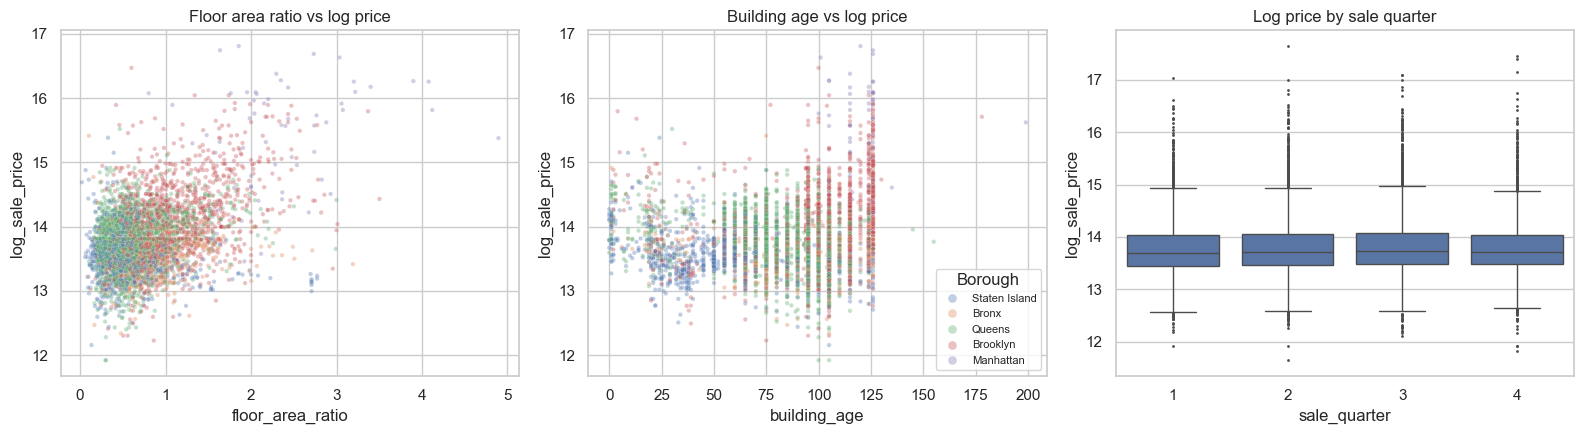

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sample = df_feat.sample(5_000, random_state=RANDOM_STATE)
boroughs = ["Staten Island", "Bronx", "Queens", "Brooklyn", "Manhattan"]   # same colours in both plots

sns.scatterplot(data=sample, x="floor_area_ratio", y="log_sale_price", hue="borough_name", hue_order=boroughs,
                alpha=0.35, s=10, ax=axes[0], legend=False)
axes[0].set_title("Floor area ratio vs log price")

sns.scatterplot(data=sample, x="building_age", y="log_sale_price", hue="borough_name", hue_order=boroughs,
                alpha=0.35, s=10, ax=axes[1])
axes[1].set_title("Building age vs log price")
axes[1].legend(title="Borough", markerscale=2, fontsize=8)

sns.boxplot(data=df_feat, x="sale_quarter", y="log_sale_price", ax=axes[2], fliersize=1)
axes[2].set_title("Log price by sale quarter")

plt.tight_layout()
plt.show()

**Observations**
- After the cleaning in 4a, **`log_gross_sqft` correlates 0.62 with log price, up from 0.38 in the EDA** (3.8). Removing the non-market sales and package deals took a lot of noise out of the size-price relationship, which is direct evidence that the cleaning was worthwhile.
- **`floor_area_ratio` is the second-strongest numeric feature (Pearson about 0.43)**, much stronger than land size on its own (about 0.08). Dividing building size by plot size created a useful signal: in the scatter plot, the densely built homes (ratio above about 1.5) are mostly in Brooklyn and Manhattan and sell for the highest prices, while Staten Island homes sit at low ratios. The ratio partly acts as a measure of **how urban** the location is.
- `building_age` has a weak overall correlation (about 0.13), but the scatter plot shows the relationship is **U-shaped, not linear**. New homes (under about 15 years) sell at a premium. Homes about 25–50 years old, mostly 1975–2000 suburban houses in Staten Island, are the cheapest. The oldest, pre-war homes, many in Brooklyn, are expensive again. Much of this is an effect of **location rather than age itself**. A linear model can only fit a straight line here, while tree-based models can capture the U-shape, which is one argument for comparing both. The vertical stripe at 125 years is the cluster of build years recorded as exactly 1900, the estimated years noted in 3.5.
- `has_commercial` has a small positive effect (mixed-use buildings tend to be larger and on commercial streets).
- `sale_quarter` has almost no linear correlation (about 0.01). The box plots show only a small summer (Q3) rise. It is kept as a minor feature; the models and the feature importance in Section 6 will show whether it helps.

#### Location features
Location is the strongest driver of price (3.6), and the data contains three location columns at different levels of detail:

| Column | Distinct values | Decision |
|---|---|---|
| `borough_name` | 5 | **Keep.** Few categories → one-hot encoding in 4d |
| `neighborhood` | about 230 | **Keep.** Too many for one-hot → **mean target encoding** in 4d (each neighbourhood is replaced by its average log price, learned on the training set only) |
| `zip_code` | about 160 | **Keep.** Also target-encoded in 4d. At first sight it looks redundant with `neighborhood`, but the two divide the city differently: most ZIP codes cross neighbourhood borders and most neighbourhoods contain several ZIP codes (see below). Together they locate a home more precisely than either alone. This was **tested, not assumed**: see the cross-validation check at the end of 4d |

`building_class_at_time_of_sale` (18 detailed classes, e.g. A1 = two-storey detached, A5 = attached row house) is also kept. It describes the **style** of the house, which `home_type` (1/2/3 family) does not.

In [44]:
print("Neighbourhoods:", df_feat["neighborhood"].nunique(), "| ZIP codes:", df_feat["zip_code"].nunique())
print("ZIP codes per neighbourhood (median):",
      df_feat.groupby("neighborhood")["zip_code"].nunique().median())
print("ZIP codes that cross more than one neighbourhood:",
      df_feat.groupby("zip_code")["neighborhood"].nunique().gt(1).sum())
df_feat["building_class_at_time_of_sale"].value_counts().head(10).to_frame("sales")

Neighbourhoods: 229 | ZIP codes: 163
ZIP codes per neighbourhood (median): 2.0
ZIP codes that cross more than one neighbourhood: 127


,sales
building_class_at_time_of_sale,
A1,3620
A5,3167
B2,2212
B1,2057
C0,1868
B3,1715
A2,1482
B9,704
A9,545


#### Final feature set
The raw columns that have been replaced by engineered versions are removed, so the same information does not enter the model twice (e.g. `year_built` and `building_age` would be perfectly correlated within a single sale year).

In [45]:
TARGET = "log_sale_price"

NUMERIC_FEATURES = ["log_gross_sqft", "log_land_sqft", "floor_area_ratio", "building_age"]
BINARY_FEATURES = ["has_commercial"]
ORDINAL_FEATURES = ["home_type"]                                            # 1- < 2- < 3-family
ONEHOT_FEATURES = ["borough_name", "building_class_at_time_of_sale", "sale_quarter"]
TARGET_ENC_FEATURES = ["neighborhood", "zip_code"]

FEATURES = NUMERIC_FEATURES + BINARY_FEATURES + ORDINAL_FEATURES + ONEHOT_FEATURES + TARGET_ENC_FEATURES

model_df = df_feat[FEATURES + [TARGET, "sale_price"]].copy()   # sale_price kept only to evaluate in dollars

pd.DataFrame({
    "feature": FEATURES,
    "group": (["numeric"] * len(NUMERIC_FEATURES) + ["binary"] * len(BINARY_FEATURES)
              + ["ordinal"] * len(ORDINAL_FEATURES) + ["one-hot"] * len(ONEHOT_FEATURES)
              + ["target-encoded"] * len(TARGET_ENC_FEATURES)),
    "missing values": model_df[FEATURES].isna().sum().values,
})

,feature,group,missing values
0,log_gross_sqft,numeric,77
1,log_land_sqft,numeric,76
2,floor_area_ratio,numeric,77
3,building_age,numeric,10
4,has_commercial,binary,76
5,home_type,ordinal,0
6,borough_name,one-hot,0
7,building_class_at_time_of_sale,one-hot,0
8,sale_quarter,one-hot,0
9,neighborhood,target-encoded,0


In [46]:
print(f"Modelling dataset: {model_df.shape[0]:,} rows, {len(FEATURES)} features + target")

Modelling dataset: 18,664 rows, 11 features + target


### 4c. Train / validation / test split
The data is split into three parts with a **70 / 15 / 15** ratio:

| Set | Share | Used for |
|---|---|---|
| **Training** | 70% | Fitting the preprocessing steps (4d) and the models. Hyperparameters are tuned with **k-fold cross-validation inside the training set** |
| **Validation** | 15% | Comparing the tuned models with each other and choosing the final model, on data none of them was trained on |
| **Test** | 15% | Used **once**, at the very end, to report the final model's performance on completely unseen data |

Keeping the test set untouched until the end matters. If we chose the model or its settings by looking at test scores, the test score would no longer be an honest estimate of performance on new sales.

**Why a stratified split?** For regression, a plain random split works when the target is evenly distributed. Our target has **extreme values** (luxury homes in the right tail). With a purely random split, one set could by chance receive many more expensive homes than another, and the scores would not be comparable. We therefore **stratify on price bands**: `log_sale_price` is cut into 10 equal-sized bins (deciles), and each set receives the same share of every bin.

In [47]:
from sklearn.model_selection import train_test_split

X = model_df[FEATURES]
y = model_df[TARGET]

# 10 price bands with (almost) equal numbers of sales, used only to stratify the split
price_band = pd.qcut(y, q=10, labels=False)

# Step 1: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp, band_train, band_temp = train_test_split(
    X, y, price_band, test_size=0.30, stratify=price_band, random_state=RANDOM_STATE)

# Step 2: split the temporary 30% in half -> 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=band_temp, random_state=RANDOM_STATE)

split_sizes = pd.DataFrame({
    "rows": [len(X_train), len(X_val), len(X_test)],
}, index=["train", "validation", "test"])
split_sizes["share"] = (split_sizes["rows"] / split_sizes["rows"].sum() * 100).round(1).astype(str) + "%"
split_sizes

,rows,share
train,13064,70.0%
validation,2800,15.0%
test,2800,15.0%


#### Checking that the three sets are comparable
If the split worked, the target should have practically the same distribution in all three sets, and the boroughs should appear in similar proportions.

In [48]:
def price_summary(target):
    dollars = np.exp(target)
    return pd.Series({
        "mean log price": target.mean(),
        "std log price":  target.std(),
        "median price ($)": dollars.median(),
        "Q1 price ($)": dollars.quantile(0.25),
        "Q3 price ($)": dollars.quantile(0.75),
        "max price ($)": dollars.max(),
    })

pd.DataFrame({"train": price_summary(y_train),
              "validation": price_summary(y_val),
              "test": price_summary(y_test)}).round(2)

,train,validation,test
mean log price,13.79,13.78,13.79
std log price,0.53,0.51,0.54
median price ($),"900,000.00","900,000.00","900,000.00"
Q1 price ($),"703,950.00","705,000.00","705,000.00"
Q3 price ($),"1,260,826.00","1,271,250.00","1,255,250.00"
max price ($),"38,000,000.00","11,600,000.00","46,000,000.00"


In [49]:
borough_share = pd.DataFrame({
    "train":      X_train["borough_name"].value_counts(normalize=True),
    "validation": X_val["borough_name"].value_counts(normalize=True),
    "test":       X_test["borough_name"].value_counts(normalize=True),
}).mul(100).round(1)
borough_share["test rows"] = X_test["borough_name"].value_counts()
borough_share

,train,validation,test,test rows
borough_name,,,,
Queens,40.00,41.50,41.50,1163
Brooklyn,28.70,27.90,28.00,785
Staten Island,19.30,19.10,18.60,520
Bronx,10.90,10.10,10.50,295
Manhattan,1.10,1.50,1.30,37


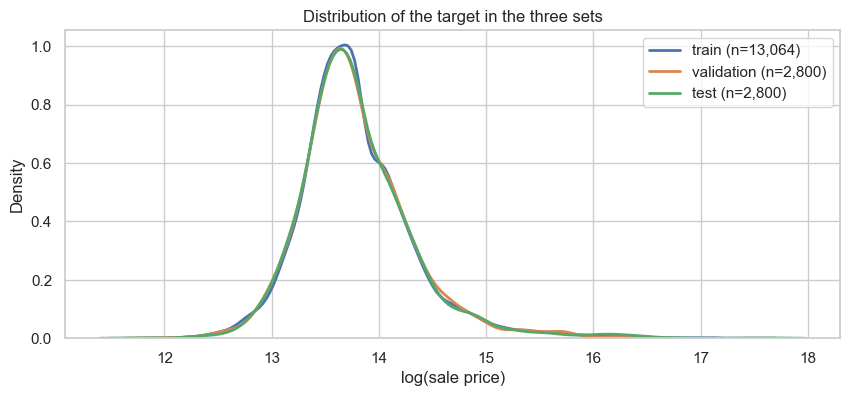

In [50]:
plt.figure(figsize=(10, 4))
for name, target in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    sns.kdeplot(target, label=f"{name} (n={len(target):,})", fill=False, linewidth=2)
plt.xlabel("log(sale price)")
plt.title("Distribution of the target in the three sets")
plt.legend()
plt.show()

**Observations:** the three sets are practically identical in their price distribution: the median is \$900k in all three, the quartiles differ by less than 2%, and the density curves lie on top of each other. Only the **maximum** differs, because the single most expensive sale (\$46M) happened to land in the test set. Stratifying can balance the shape of a distribution but not individual extreme values, and this one sale will inflate squared-error metrics (MSE/RMSE) on the test set, which must be kept in mind in Section 6. The borough proportions also match closely, even though we did not stratify on borough directly: price bands and boroughs are strongly linked, so stratifying on price also balances the boroughs. Performance on the validation and test sets will therefore be comparable with each other and representative of the full data.

**Limitation:** Manhattan has only a few dozen homes in each of the validation and test sets, so any per-borough error reported for Manhattan will be much less reliable than for the other boroughs.

### 4d. Missing values, scaling and encoding (preprocessing pipeline)
These steps **learn values from the data** (medians, means, standard deviations, category lists, average price per neighbourhood). They are therefore built as a scikit-learn `Pipeline` / `ColumnTransformer` that is **fitted on the training set only** and then applied unchanged to the validation and test sets:

1. **Split** (done in 4c)
2. **Fit** the imputers, scalers and encoders on `X_train`
3. **Transform** train, validation and test with the fitted steps
4. **Train and evaluate** the models (Sections 5–6)

Putting every step inside the pipeline also means that during cross-validation the steps are re-fitted on each training fold, so the validation fold never influences them.

| Feature group | Columns | Missing values | Encoding / scaling | Justification |
|---|---|---|---|---|
| Numeric | `log_gross_sqft`, `log_land_sqft`, `floor_area_ratio`, `building_age` | **Median** imputation | `StandardScaler` (z-score) | The median is robust to the skew and outliers seen in the EDA, where the mean would be pulled by extreme values. Scaling puts all features on the same range, which **KNN** (distance-based) and **linear models** need; tree models are not affected by it |
| Missing-size flag | `size_missing` (from `log_gross_sqft`) | — | 0/1 indicator | The missing sizes are not random: they are co-op bungalow communities (4a). The flag lets the model learn that these homes differ, instead of treating the filled-in median as a real size |
| Binary | `has_commercial` | **Most frequent** value (0) | none (already 0/1) | 97% of homes have no commercial unit |
| Ordinal | `home_type` | none missing | `OrdinalEncoder` (1-family = 0 < 2-family = 1 < 3-family = 2), then scaled | The categories have a natural order (more units), which a single ordered number preserves |
| Nominal, few categories | `borough_name`, `building_class_at_time_of_sale`, `sale_quarter` | none missing | `OneHotEncoder` | No natural order, so each category becomes its own 0/1 column. Rare building classes (< 20 sales) are grouped into one "infrequent" column so that the model does not learn from a handful of examples |
| Nominal, many categories | `neighborhood` (229 values) | none missing | **Mean target encoding** (`TargetEncoder`), then scaled | One-hot would create 229 sparse columns. Target encoding replaces each neighbourhood with its average log price, a single, highly informative number |

**Avoiding leakage in target encoding.** Target encoding uses the target itself, so it is the most leakage-prone step. scikit-learn's `TargetEncoder` handles this in two ways. (1) **Cross-fitting:** when fitting on the training set, each row's encoding is computed from the *other* folds, never from the row's own price. (2) **Shrinkage (smoothing):** a neighbourhood's average is blended with the overall average, and the blend depends on how reliable the neighbourhood's own average is. The default `smooth="auto"` estimates this from the data; a fixed number can be set instead. The choice is tested below.

In [51]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, TargetEncoder

HOME_TYPE_ORDER = [["1-family", "2-family", "3-family"]]

def make_preprocessor(te_smooth="auto", te_features=None):
    """Build a fresh (unfitted) preprocessing step. Called once per model so each model gets its own copy.
    te_features: the target-encoded columns (default TARGET_ENC_FEATURES); only changed for the ZIP check in 4d."""
    if te_features is None:
        te_features = TARGET_ENC_FEATURES
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale",  StandardScaler()),
    ])
    binary = SimpleImputer(strategy="most_frequent")
    ordinal = Pipeline([
        ("encode", OrdinalEncoder(categories=HOME_TYPE_ORDER)),
        ("scale",  StandardScaler()),
    ])
    onehot = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False)
    target_enc = Pipeline([
        # cv = the folds used for cross-fitting (shuffled, fixed seed for reproducibility)
        ("encode", TargetEncoder(target_type="continuous", smooth=te_smooth,
                                 cv=KFold(5, shuffle=True, random_state=RANDOM_STATE))),
        ("scale",  StandardScaler()),
    ])

    return ColumnTransformer([
        ("num",          numeric,            NUMERIC_FEATURES),
        ("size_missing", MissingIndicator(), ["log_gross_sqft"]),
        ("bin",          binary,             BINARY_FEATURES),
        ("ord",          ordinal,            ORDINAL_FEATURES),
        ("ohe",          onehot,             ONEHOT_FEATURES),
        ("te",           target_enc,         te_features),
    ], verbose_feature_names_out=False)

preprocessor = make_preprocessor()
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('size_missing', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per tr

#### Fit on the training set only, then transform all three sets

In [52]:
X_train_prep = preprocessor.fit_transform(X_train, y_train)   # learns medians, scales, categories, encodings
X_val_prep   = preprocessor.transform(X_val)                  # only APPLIES what was learned
X_test_prep  = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("Shape after preprocessing:")
print(f"  train      {X_train_prep.shape}")
print(f"  validation {X_val_prep.shape}")
print(f"  test       {X_test_prep.shape}")
print("\nMissing values left:",
      int(np.isnan(X_train_prep).sum() + np.isnan(X_val_prep).sum() + np.isnan(X_test_prep).sum()))
print(f"\n{len(feature_names)} model input columns:")
print(list(feature_names))

Shape after preprocessing:
  train      (13064, 35)
  validation (2800, 35)
  test       (2800, 35)

Missing values left: 0

35 model input columns:
['log_gross_sqft', 'log_land_sqft', 'floor_area_ratio', 'building_age', 'missingindicator_log_gross_sqft', 'has_commercial', 'home_type', 'borough_name_Bronx', 'borough_name_Brooklyn', 'borough_name_Manhattan', 'borough_name_Queens', 'borough_name_Staten Island', 'building_class_at_time_of_sale_A0', 'building_class_at_time_of_sale_A1', 'building_class_at_time_of_sale_A2', 'building_class_at_time_of_sale_A3', 'building_class_at_time_of_sale_A4', 'building_class_at_time_of_sale_A5', 'building_class_at_time_of_sale_A6', 'building_class_at_time_of_sale_A8', 'building_class_at_time_of_sale_A9', 'building_class_at_time_of_sale_B1', 'building_class_at_time_of_sale_B2', 'building_class_at_time_of_sale_B3', 'building_class_at_time_of_sale_B9', 'building_class_at_time_of_sale_C0', 'building_class_at_time_of_sale_S1', 'building_class_at_time_of_sale_

#### Checking the fitted steps
The values below were learned from the training set only. The medians used to fill the gaps are shown on the original (log) scale.

In [53]:
num_imputer = preprocessor.named_transformers_["num"].named_steps["impute"]
pd.DataFrame({
    "median learned on train": num_imputer.statistics_,
    "missing in train": X_train[NUMERIC_FEATURES].isna().sum().values,
    "missing in validation": X_val[NUMERIC_FEATURES].isna().sum().values,
    "missing in test": X_test[NUMERIC_FEATURES].isna().sum().values,
}, index=NUMERIC_FEATURES).round(3)

,median learned on train,missing in train,missing in validation,missing in test
log_gross_sqft,7.49,55,14,8
log_land_sqft,7.82,54,14,8
floor_area_ratio,0.65,55,14,8
building_age,90.00,7,2,1


In [54]:
# After StandardScaler the numeric columns should have mean 0 and std 1 on the TRAINING set.
# On validation/test they are only close to 0 and 1, because the scaler was not fitted on them.
scaled_cols = NUMERIC_FEATURES + ["home_type", "neighborhood"]
idx = [list(feature_names).index(c) for c in scaled_cols]

pd.DataFrame({
    "train mean": X_train_prep[:, idx].mean(axis=0),
    "train std":  X_train_prep[:, idx].std(axis=0),
    "val mean":   X_val_prep[:, idx].mean(axis=0),
    "val std":    X_val_prep[:, idx].std(axis=0),
}, index=scaled_cols).round(3)

,train mean,train std,val mean,val std
log_gross_sqft,-0.00,1.00,0.01,1.00
log_land_sqft,-0.00,1.00,-0.03,0.99
floor_area_ratio,0.00,1.00,0.04,1.03
building_age,0.00,1.00,0.03,0.98
home_type,-0.00,1.00,0.04,1.02
neighborhood,-0.00,1.00,-0.00,1.01


In [55]:
# What the target encoder learned: average log price per neighbourhood (shown back in dollars)
te = preprocessor.named_transformers_["te"].named_steps["encode"]
neigh_enc = pd.DataFrame({
    "neighbourhood": te.categories_[0],
    "encoded log price": te.encodings_[0],
})
neigh_enc["≈ typical price ($)"] = np.exp(neigh_enc["encoded log price"]).round(-3)
neigh_enc["training sales"] = neigh_enc["neighbourhood"].map(X_train["neighborhood"].value_counts())

print("Most expensive neighbourhoods (encoded):")
display(neigh_enc.sort_values("encoded log price", ascending=False).head(5))
print("Cheapest neighbourhoods (encoded):")
display(neigh_enc.sort_values("encoded log price").head(5))

Most expensive neighbourhoods (encoded):


,neighbourhood,encoded log price,≈ typical price ($),training sales
72,FLATIRON,16.04,"9,294,000.00",1
93,GREENWICH VILLAGE-WEST,15.96,"8,521,000.00",24
133,MIDTOWN WEST,15.82,"7,400,000.00",1
204,UPPER EAST SIDE (79-96),15.81,"7,355,000.00",16
92,GREENWICH VILLAGE-CENTRAL,15.75,"6,946,000.00",6


Cheapest neighbourhoods (encoded):


,neighbourhood,encoded log price,≈ typical price ($),training sales
25,BROAD CHANNEL,13.09,"482,000.00",13
163,PORT IVORY,13.12,"497,000.00",10
46,CONCORD-FOX HILLS,13.14,"510,000.00",8
45,CONCORD,13.17,"526,000.00",31
145,NEW DORP-BEACH,13.25,"568,000.00",41


In [56]:
# The encoded neighbourhood should now be a strong numeric predictor of price
enc_col = list(feature_names).index("neighborhood")
r = np.corrcoef(X_train_prep[:, enc_col], y_train)[0, 1]
print(f"Correlation of encoded neighbourhood with log price (train): {r:.2f}")

Correlation of encoded neighbourhood with log price (train): 0.75


#### Choosing the target-encoding smoothing
We compare `smooth="auto"` with fixed values using **5-fold cross-validation on the training set only** (the validation and test sets are not touched). A plain Linear Regression is used as a quick, neutral model for the comparison. Larger values pull every neighbourhood more strongly towards the overall average.

In [57]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

small = X_train["neighborhood"].value_counts()
print(f"Neighbourhoods with fewer than 5 training sales: {(small < 5).sum()} "
      f"({small[small < 5].sum()} rows, {small[small < 5].sum() / len(X_train):.1%} of training data)\n")

cv5 = KFold(5, shuffle=True, random_state=RANDOM_STATE)
smoothing_results = {}
for smooth in ["auto", 2, 5, 10, 20, 50]:
    pipe = Pipeline([("prep", make_preprocessor(te_smooth=smooth)), ("model", LinearRegression())])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv5, scoring="neg_root_mean_squared_error")
    smoothing_results[str(smooth)] = -scores.mean()

# shown with 4 decimals: the differences are small but consistent
pd.Series(smoothing_results, name="CV RMSE (log price)").map("{:.4f}".format).to_frame()

Neighbourhoods with fewer than 5 training sales: 20 (41 rows, 0.3% of training data)



,CV RMSE (log price)
auto,0.2791
2,0.2799
5,0.2814
10,0.2837
20,0.2875
50,0.2949


**Decision:** `smooth="auto"` gives the **lowest cross-validated error**, and the error rises steadily as the smoothing gets stronger. Strong smoothing erases real price differences between neighbourhoods, which costs much more accuracy than the occasional over-confident encoding of a tiny neighbourhood. Those tiny neighbourhoods are only about 0.3% of the training rows, and the borough one-hot columns still give the model a sensible location for them. We therefore keep `smooth="auto"`, and note the limitation.

#### Is ZIP code redundant with neighbourhood?
Keeping `zip_code` (4b) was checked here with **5-fold cross-validation on the training set only**, before any tuning, so the validation and test sets play no part in the decision. Three location options are compared with two different model families (a linear model and gradient boosting, both with fixed default settings). Every option uses the same folds, so the per-fold errors can be compared directly.

In [58]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

location_options = {
    "neighbourhood only":       ["neighborhood"],
    "ZIP code only":            ["zip_code"],
    "neighbourhood + ZIP code": ["neighborhood", "zip_code"],
}
check_models = {
    "Ridge": Ridge(alpha=1.0),
    "Gradient Boosting": HistGradientBoostingRegressor(early_stopping=False, random_state=RANDOM_STATE),
}

fold_rmse = {}
for option, te_cols in location_options.items():
    for model_name, model in check_models.items():
        pipe = Pipeline([("prep", make_preprocessor(te_features=te_cols)), ("model", model)])
        fold_rmse[(model_name, option)] = -cross_val_score(pipe, X_train, y_train, cv=cv5,
                                                           scoring="neg_root_mean_squared_error")

zip_check = pd.DataFrame([
    {"model": m, "location features": o, "CV RMSE (log)": s.mean(),
     "folds better than neighbourhood only": int((s < fold_rmse[(m, "neighbourhood only")]).sum())}
    for (m, o), s in fold_rmse.items()
]).set_index(["model", "location features"])
zip_check.style.format({"CV RMSE (log)": "{:.4f}"})

,,CV RMSE (log),folds better than neighbourhood only
model,location features,,
Ridge,neighbourhood only,0.2842,0
Gradient Boosting,neighbourhood only,0.2784,0
Ridge,ZIP code only,0.2883,0
Gradient Boosting,ZIP code only,0.2817,0
Ridge,neighbourhood + ZIP code,0.2791,5
Gradient Boosting,neighbourhood + ZIP code,0.2734,5


**Decision: keep ZIP code.** Adding it next to neighbourhood lowers the CV error for **both** model families (Ridge 0.2842 → 0.2791, Gradient Boosting 0.2784 → 0.2734) and in **all 5 folds**, so the gain is consistent and not the luck of one split. Using ZIP code *instead of* neighbourhood is worse for both models, so the two columns are not interchangeable: neighbourhood is the stronger single description of location, and ZIP code refines it. 127 of the 163 ZIP codes cross a neighbourhood border, so one neighbourhood can be split into parts with different price levels.

The first plan (dropping ZIP code as redundant) was therefore wrong, and the feature set was changed. A third column combining neighbourhood and ZIP code (472 categories) was also tried in a separate check. It lowered the CV error by only about 0.0003 more, too little to justify another sparse encoded column with many tiny categories.

**Observations**
- The pipeline turns the 11 features into the model input columns listed above, with **no missing values** left in any set.
- The scaled columns have mean 0 and standard deviation 1 on the training set, and only *close* to those values on the validation set. This is expected and shows the scaler was fitted on the training data only.
- The **target-encoded neighbourhood** (correlation 0.75 with log price on train) is now by far the strongest single predictor of price (compare with log building size at about 0.62 in 4b). It turns location, the main price driver found in the EDA, into one number that every model can use, including the linear model and KNN.
- The most and least expensive encoded neighbourhoods match what one would expect for New York (central Manhattan at the top, outer areas of Queens and Staten Island at the bottom), which is a useful sanity check.
- **A weakness of the automatic smoothing:** some neighbourhoods have only 1 sale in the training set (e.g. Flatiron), and they still receive an extreme encoding. With one sale, the spread of prices *inside* the neighbourhood is zero, so `smooth="auto"` treats the single price as fully reliable and does not shrink it. The check below shows how much this matters and whether a fixed smoothing value is better.

The same `make_preprocessor()` is used inside every model's pipeline in Section 5, so all models are trained on identically prepared data and the comparison between them is fair.

### 4e. Data preparation summary
| Step | Action | Result |
|---|---|---|
| Errors | Removed rebuilt/converted properties (150), package sales (181) and non-market low-price outliers (650); corrected impossible units and sizes | 19,645 → **18,664** rows (95% kept) |
| Columns | Dropped 12 empty, constant, redundant, post-sale or identifier columns | 11 columns kept |
| Feature engineering | Building age, log sizes, floor area ratio, commercial flag, sale quarter, log target | Floor area ratio adds a strong new signal (r ≈ 0.43) |
| Split | Stratified 70 / 15 / 15 on price deciles | Train 13,064 · validation 2,800 · test 2,800 |
| Missing values | Median imputation + missing-size indicator; most-frequent for the binary flag | No missing values left |
| Scaling | StandardScaler on all numeric and ordinal columns | Fitted on train only |
| Encoding | Ordinal (home type), one-hot (borough, building class, quarter), target encoding (neighbourhood, ZIP code) | Fitted on train only, with cross-fitting |

## 5. Model training and hyperparameter tuning

Four regression models are trained, chosen to cover the main families taught in the module and to move from simple to complex:

| Model | Family | Why it is included |
|---|---|---|
| **Linear Regression (Ridge)** | Linear | Simple, fast and interpretable **baseline**. If a complex model cannot beat it, the complexity is not worth it. Ridge adds an L2 penalty that keeps the many one-hot coefficients stable. |
| **K-Nearest Neighbours** | Instance-based | Predicts a home's price from the most similar homes sold, which is how property valuers work ("comparables"). Needs scaled features, which the pipeline provides. |
| **Random Forest** | Ensemble, bagging | Averages many deep decision trees trained on bootstrap samples. Captures non-linear effects (e.g. the U-shaped building age) and interactions without feature engineering, and is robust to outliers. |
| **Histogram Gradient Boosting** | Ensemble, boosting | Builds trees one after another, each correcting the errors of the previous ones. This is scikit-learn's implementation of the LightGBM approach and is usually the most accurate model family on tabular data. It is used instead of XGBoost because XGBoost needs an extra system library (OpenMP) on macOS, which would break reproducibility. |

**Tuning method.** Every model is a single `Pipeline` of `make_preprocessor()` + the model, so the encoders and scaler are re-fitted inside each cross-validation fold and no information leaks from the held-out fold. Hyperparameters are chosen with `GridSearchCV` using **5-fold cross-validation on the training set only**. The selection score is **RMSE on the log price**, which treats a 10% error on a cheap home and on an expensive home equally. MAE is recorded as well. The validation set is used afterwards to compare the tuned models, and the test set is kept untouched until Section 6.

In [59]:
import time
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}
tuned = {}       # fitted GridSearchCV objects, one per model
cv_tables = {}   # full cross-validation results, one per model


def tune(name, model, param_grid):
    """Grid-search one model inside the full preprocessing pipeline (5-fold CV on train)."""
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
    grid = {f"model__{k}": v for k, v in param_grid.items()}
    search = GridSearchCV(pipe, grid, cv=cv5, scoring=SCORING, refit="rmse", n_jobs=-1)
    start = time.time()
    search.fit(X_train, y_train)
    tuned[name] = search

    res = pd.DataFrame(search.cv_results_)
    table = pd.DataFrame({
        **{k.replace("param_model__", ""): res[k] for k in res if k.startswith("param_model__")},
        "CV RMSE (log)": -res["mean_test_rmse"],
        "CV RMSE std": res["std_test_rmse"],
        "CV MAE (log)": -res["mean_test_mae"],
    }).sort_values("CV RMSE (log)")
    cv_tables[name] = table

    best = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    print(f"{name}: {len(res)} combinations x 5 folds in {time.time() - start:.0f}s")
    print(f"Best parameters: {best}")
    print(f"Best CV RMSE (log): {-search.best_score_:.4f}")
    return table.head(10).style.format(precision=4)

### 5.1 Linear Regression (Ridge) — baseline
The only hyperparameter is `alpha`, the strength of the L2 penalty. `alpha` close to 0 is ordinary least squares; larger values shrink the coefficients.

In [60]:
tune("Linear (Ridge)", Ridge(), {"alpha": [0.01, 0.1, 1, 3, 10, 30, 100]})

Linear (Ridge): 7 combinations x 5 folds in 4s
Best parameters: {'alpha': 0.1}
Best CV RMSE (log): 0.2790


,alpha,CV RMSE (log),CV RMSE std,CV MAE (log)
1,0.1000,0.2790,0.0087,0.2004
0,0.0100,0.2791,0.0087,0.2005
2,1.0000,0.2791,0.0088,0.2005
3,3.0000,0.2792,0.0088,0.2006
4,10.0000,0.2793,0.0088,0.2007
5,30.0000,0.2794,0.0087,0.2008
6,100.0000,0.2798,0.0087,0.2010


### 5.2 K-Nearest Neighbours
- `n_neighbors` (k): small k follows the data closely (low bias, high variance), large k averages over many homes (smoother, higher bias). Odd values are used, as in the lecture.
- `weights`: `uniform` gives every neighbour the same vote, `distance` gives closer homes more weight.
- `p`: 1 = Manhattan distance, 2 = Euclidean distance.

In [61]:
tune("KNN", KNeighborsRegressor(), {
    "n_neighbors": [5, 9, 15, 21, 31, 45],
    "weights": ["uniform", "distance"],
    "p": [1, 2],
})

KNN: 24 combinations x 5 folds in 8s
Best parameters: {'n_neighbors': 31, 'p': 2, 'weights': 'distance'}
Best CV RMSE (log): 0.2867


,n_neighbors,p,weights,CV RMSE (log),CV RMSE std,CV MAE (log)
19,31,2,distance,0.2867,0.0085,0.2028
15,21,2,distance,0.2869,0.0087,0.2035
23,45,2,distance,0.2872,0.0087,0.2028
11,15,2,distance,0.2879,0.0078,0.2047
13,21,1,distance,0.2885,0.0086,0.2048
14,21,2,uniform,0.2887,0.0094,0.2052
17,31,1,distance,0.2887,0.0086,0.2045
18,31,2,uniform,0.2889,0.0090,0.2047
10,15,2,uniform,0.2890,0.0084,0.2059
9,15,1,distance,0.2893,0.0082,0.2056


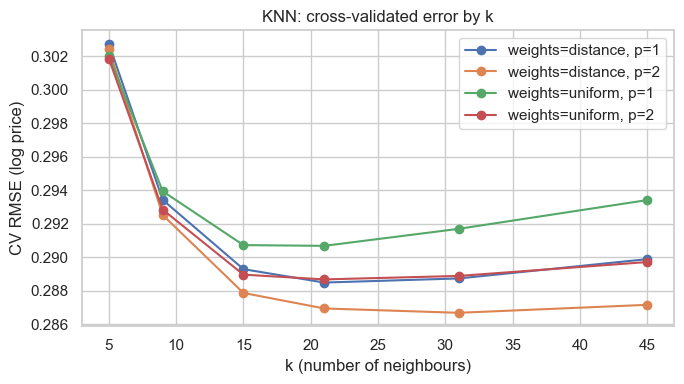

In [62]:
# How the CV error changes with k (best weights/p setting for each k)
knn_cv = cv_tables["KNN"]
fig, ax = plt.subplots(figsize=(7, 4))
for (w, p), grp in knn_cv.groupby(["weights", "p"]):
    grp = grp.sort_values("n_neighbors")
    ax.plot(grp["n_neighbors"], grp["CV RMSE (log)"], marker="o", label=f"weights={w}, p={p}")
ax.set_xlabel("k (number of neighbours)")
ax.set_ylabel("CV RMSE (log price)")
ax.set_title("KNN: cross-validated error by k")
ax.legend()
plt.tight_layout()
plt.show()

**Observations (KNN)**
- The error falls steeply from k = 5 to about k = 21–31 and then rises again: very small k copies the noise of a few individual sales (overfitting), large k averages over homes that are no longer similar (underfitting). The best value, **k = 31**, is inside the tested range (k = 45 is slightly worse).
- **Distance weighting** and **Euclidean distance (p = 2)** are consistently better, so the most similar homes should count most.
- Note: with distance weighting each training home is its own nearest neighbour, so the KNN *training* error below is artificially low and is not a sign of a problem on new data.

### 5.3 Random Forest
- `max_features`: share of features tried at each split. Smaller values make the trees more different from each other, which is what makes averaging them useful.
- `min_samples_leaf`: the minimum number of homes in a leaf. Larger values stop single unusual sales from getting their own leaf (less overfitting).

Tree depth is not limited separately: `min_samples_leaf` already controls how far each tree grows, and a first test with `max_depth=20` gave the same error as unlimited depth.

`n_estimators` is fixed at 300: more trees never make a random forest worse, they only cost time, and the error has flattened out well before 300 trees.

In [63]:
tune("Random Forest", RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1), {
    "max_features": [0.15, 0.25, 0.33, 0.5, 1.0],
    "min_samples_leaf": [1, 3, 5, 10],
})

Random Forest: 20 combinations x 5 folds in 102s
Best parameters: {'max_features': 0.25, 'min_samples_leaf': 3}
Best CV RMSE (log): 0.2736


,max_features,min_samples_leaf,CV RMSE (log),CV RMSE std,CV MAE (log)
5,0.2500,3,0.2736,0.0083,0.1939
9,0.3300,3,0.2741,0.0081,0.1947
10,0.3300,5,0.2742,0.0086,0.1945
6,0.2500,5,0.2746,0.0085,0.1943
4,0.2500,1,0.2749,0.0079,0.1954
14,0.5000,5,0.2750,0.0084,0.1958
13,0.5000,3,0.2751,0.0085,0.1960
8,0.3300,1,0.2752,0.0084,0.1960
1,0.1500,3,0.2760,0.0083,0.1949
11,0.3300,10,0.2760,0.0087,0.1957


### 5.4 Histogram Gradient Boosting
- `learning_rate`: how much each new tree corrects the previous ones. Smaller values need more trees but usually generalise better.
- `max_iter`: the number of boosting rounds (trees).
- `max_leaf_nodes`: the size of each tree, which controls how complex the interactions it can learn are.
- `min_samples_leaf`: as for the random forest, protects against fitting single unusual sales.

Early stopping is switched off so that every combination is trained for exactly `max_iter` rounds and the grid search, not an internal split, decides how many trees to use.

In [64]:
tune("Gradient Boosting", HistGradientBoostingRegressor(early_stopping=False, random_state=RANDOM_STATE), {
    "learning_rate": [0.01, 0.03, 0.1],
    "max_iter": [150, 300, 600, 1000, 1500, 2000],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [20, 50],
})

Gradient Boosting: 108 combinations x 5 folds in 327s
Best parameters: {'learning_rate': 0.01, 'max_iter': 1000, 'max_leaf_nodes': 31, 'min_samples_leaf': 20}
Best CV RMSE (log): 0.2728


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,CV RMSE (log),CV RMSE std,CV MAE (log)
20,0.0100,1000,31,20,0.2728,0.0084,0.1942
48,0.0300,600,15,20,0.2729,0.0091,0.1944
24,0.0100,1500,15,20,0.2729,0.0091,0.1945
14,0.0100,600,31,20,0.2730,0.0086,0.1943
30,0.0100,2000,15,20,0.2731,0.0093,0.1946
44,0.0300,300,31,20,0.2732,0.0083,0.1944
26,0.0100,1500,31,20,0.2733,0.0082,0.1947
18,0.0100,1000,15,20,0.2733,0.0092,0.1948
25,0.0100,1500,15,50,0.2734,0.0095,0.1944
16,0.0100,600,63,20,0.2734,0.0082,0.1947


### 5.5 Comparing the tuned models on the validation set
Each tuned pipeline (already re-fitted on the full training set by `GridSearchCV`) now predicts the **validation set**, which none of the models has seen. Errors are reported on the log scale and, after converting predictions back with `exp`, **in dollars**, which is what a buyer or seller cares about:
- **RMSE / MAE ($)**: typical size of the error in dollars. RMSE punishes large errors more.
- **MAPE**: average error as a percentage of the true price, comparable across cheap and expensive homes.
- **Median APE**: the percentage error of a typical home, not affected by a few extreme sales.
- **R²**: share of the variation in price explained by the model.

In [65]:
def evaluate(model, X, y_log):
    """Errors on the log scale and in dollars for one fitted pipeline."""
    pred_log = model.predict(X)
    y_usd, pred_usd = np.exp(y_log), np.exp(pred_log)
    ape = np.abs(pred_usd - y_usd) / y_usd
    return {
        "RMSE (log)": np.sqrt(mean_squared_error(y_log, pred_log)),
        "MAE (log)": mean_absolute_error(y_log, pred_log),
        "R² (log)": r2_score(y_log, pred_log),
        "RMSE ($)": np.sqrt(mean_squared_error(y_usd, pred_usd)),
        "MAE ($)": mean_absolute_error(y_usd, pred_usd),
        "MAPE": ape.mean(),
        "Median APE": np.median(ape),
        "R² ($)": r2_score(y_usd, pred_usd),
    }


rows = {}
for name, search in tuned.items():
    rows[name] = {"CV RMSE (log)": -search.best_score_,
                  "Train RMSE (log)": evaluate(search.best_estimator_, X_train, y_train)["RMSE (log)"],
                  **evaluate(search.best_estimator_, X_val, y_val)}
val_results = pd.DataFrame(rows).T.sort_values("RMSE (log)")
val_results.style.format({
    "CV RMSE (log)": "{:.4f}", "Train RMSE (log)": "{:.4f}", "RMSE (log)": "{:.4f}", "MAE (log)": "{:.4f}",
    "R² (log)": "{:.3f}", "R² ($)": "{:.3f}", "RMSE ($)": "${:,.0f}", "MAE ($)": "${:,.0f}",
    "MAPE": "{:.1%}", "Median APE": "{:.1%}"})

,CV RMSE (log),Train RMSE (log),RMSE (log),MAE (log),R² (log),RMSE ($),MAE ($),MAPE,Median APE,R² ($)
Random Forest,0.2736,0.2051,0.2651,0.1893,0.732,"$444,643","$226,172",20.6%,13.5%,0.751
Gradient Boosting,0.2728,0.2416,0.2661,0.1904,0.730,"$521,981","$233,085",20.7%,13.7%,0.657
Linear (Ridge),0.2790,0.2733,0.2714,0.1967,0.719,"$473,453","$237,938",21.4%,14.4%,0.718
KNN,0.2867,0.1776,0.2746,0.1970,0.712,"$453,864","$237,135",21.2%,14.0%,0.741


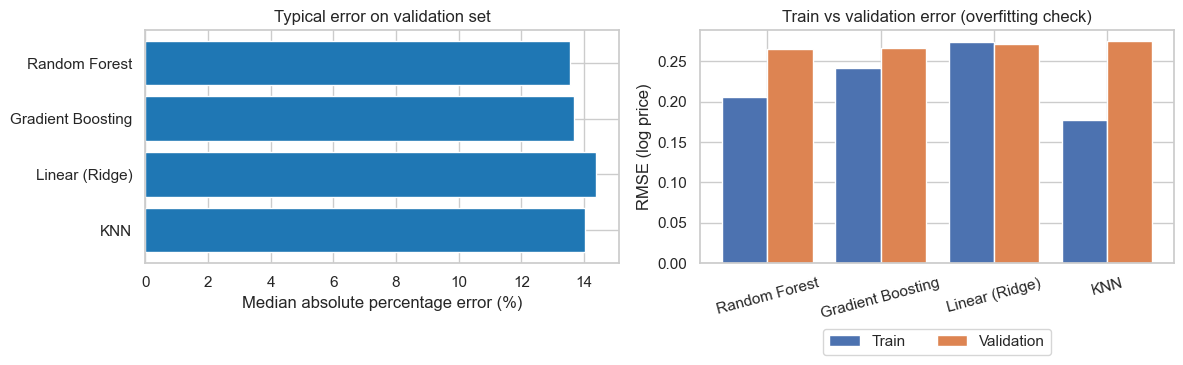

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = val_results.index
axes[0].barh(order, val_results["Median APE"] * 100, color="tab:blue")
axes[0].set_xlabel("Median absolute percentage error (%)")
axes[0].set_title("Typical error on validation set")
axes[0].invert_yaxis()
x = np.arange(len(order))
axes[1].bar(x - 0.2, val_results["Train RMSE (log)"], 0.4, label="Train")
axes[1].bar(x + 0.2, val_results["RMSE (log)"], 0.4, label="Validation")
axes[1].set_xticks(x, order, rotation=15)
axes[1].set_ylabel("RMSE (log price)")
axes[1].set_title("Train vs validation error (overfitting check)")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)
plt.tight_layout()
plt.show()

**Observations**
- **The two ensemble models are best and practically tied.** Random Forest and Gradient Boosting have almost the same validation RMSE (0.265 and 0.266 on the log scale) and median error (13.5% and 13.7%): for a typical $900k home the prediction is within roughly $120k. Their difference in CV RMSE (0.0008) is much smaller than the spread of the CV score across folds (about 0.008).
- **The gain over the linear baseline is real but modest** (validation RMSE 0.271 → 0.266, median error 14.4% → 13.7%). This tells us that most of the price signal is already captured by the prepared features, especially the target-encoded location columns and log size, which have an almost linear relationship with log price. The tree models add the non-linear parts, such as the U-shaped effect of building age.
- **KNN is the weakest model**, although it is close to the linear baseline. With 35 input columns, many of them one-hot, "nearest" homes are not always truly comparable, which is a known weakness of distance-based methods in higher dimensions.
- **Overfitting check:** the linear model has almost the same error on train and validation (it is too simple to overfit). Random Forest fits the training data much more closely than new data (0.21 vs 0.27), while Gradient Boosting has a smaller gap (0.24 vs 0.27), so it generalises more consistently.
- **The dollar metrics tell a slightly different story at the top of the market.** Random Forest has a lower RMSE in dollars ($445k vs $522k). RMSE in dollars is dominated by a handful of very expensive homes, where an error of 20% is worth millions, so this difference comes from a few sales, not from typical homes. Section 6 looks at errors by price band to check this.
- All validation errors are slightly lower than the CV errors, which suggests the validation set happens to be a little easier than average. It does not change the ranking.

**Choice of final model: Gradient Boosting (HistGradientBoostingRegressor).**
1. It has the **best cross-validation score**, which was the selection criterion decided before tuning, and it is measured on 13,064 homes rather than 2,800.
2. It shows **less overfitting** than the Random Forest.
3. The saved model is about **1.5 MB**, much smaller than a forest of 300 deep trees (tens of MB), which matters for loading it quickly in the deployed Streamlit app.

The Random Forest stays as a strong alternative and is compared again on the test set in Section 6. The final model is re-fitted on train + validation together before the test evaluation, so that it learns from as much data as possible.

In [67]:
best_params = {k.replace("model__", ""): v for k, v in tuned["Gradient Boosting"].best_params_.items()}
FINAL_MODEL_NAME = "Gradient Boosting"
print(f"Final model: {FINAL_MODEL_NAME}")
print(f"Hyperparameters: {best_params}")

Final model: Gradient Boosting
Hyperparameters: {'learning_rate': 0.01, 'max_iter': 1000, 'max_leaf_nodes': 31, 'min_samples_leaf': 20}


## 6. Final evaluation on the test set

The chosen model is now re-fitted on **train + validation together** (15,864 homes) with the hyperparameters found in Section 5, and evaluated **once** on the **test set** (2,800 homes), which has not been used for any decision so far. This gives an honest estimate of how the model will perform on new 2025-style sales. The Random Forest is evaluated the same way as a reference, and the linear baseline shows how much the final model adds.

In [68]:
from sklearn.base import clone

X_trval = pd.concat([X_train, X_val])
y_trval = pd.concat([y_train, y_val])

final_models = {}
for name in [FINAL_MODEL_NAME, "Random Forest", "Linear (Ridge)"]:
    final_models[name] = clone(tuned[name].best_estimator_).fit(X_trval, y_trval)

final_model = final_models[FINAL_MODEL_NAME]
test_results = pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in final_models.items()}).T
test_results.insert(0, "MSE (log)", test_results["RMSE (log)"] ** 2)
test_results.style.format({
    "MSE (log)": "{:.4f}", "RMSE (log)": "{:.4f}", "MAE (log)": "{:.4f}", "R² (log)": "{:.3f}", "R² ($)": "{:.3f}",
    "RMSE ($)": "${:,.0f}", "MAE ($)": "${:,.0f}", "MAPE": "{:.1%}", "Median APE": "{:.1%}"})

,MSE (log),RMSE (log),MAE (log),R² (log),RMSE ($),MAE ($),MAPE,Median APE,R² ($)
Gradient Boosting,0.0730,0.2701,0.1917,0.748,"$836,866","$259,264",20.5%,13.6%,0.675
Random Forest,0.0729,0.2700,0.1914,0.748,"$857,106","$258,747",20.4%,13.1%,0.659
Linear (Ridge),0.0764,0.2764,0.1989,0.736,"$851,038","$264,651",21.1%,14.1%,0.664


In [69]:
# Validation vs test for the final model: a large drop would mean the model was over-tuned to the validation set
pd.DataFrame({"Validation": val_results.loc[FINAL_MODEL_NAME, test_results.columns.drop("MSE (log)")],
              "Test": test_results.loc[FINAL_MODEL_NAME].drop("MSE (log)")}).T.style.format({
    "RMSE (log)": "{:.4f}", "MAE (log)": "{:.4f}", "R² (log)": "{:.3f}", "R² ($)": "{:.3f}",
    "RMSE ($)": "${:,.0f}", "MAE ($)": "${:,.0f}", "MAPE": "{:.1%}", "Median APE": "{:.1%}"})

,RMSE (log),MAE (log),R² (log),RMSE ($),MAE ($),MAPE,Median APE,R² ($)
Validation,0.2661,0.1904,0.730,"$521,981","$233,085",20.7%,13.7%,0.657
Test,0.2701,0.1917,0.748,"$836,866","$259,264",20.5%,13.6%,0.675


In [70]:
# How much of the squared dollar error comes from the single largest sale?
sq_err = (np.exp(final_model.predict(X_test)) - np.exp(y_test)) ** 2
top = np.exp(y_test).idxmax()
print(f"Largest test sale: ${np.exp(y_test[top]):,.0f}, predicted ${np.exp(final_model.predict(X_test.loc[[top]]))[0]:,.0f}")
print(f"Share of total squared dollar error from this one sale: {sq_err[top] / sq_err.sum():.0%}")
print(f"RMSE ($) without it: ${np.sqrt(sq_err.drop(top).mean()):,.0f}")

Largest test sale: $46,000,000, predicted $15,871,479
Share of total squared dollar error from this one sale: 46%
RMSE ($) without it: $613,425


**Observations**
- **The test results confirm the validation results.** Gradient Boosting and Random Forest are again practically tied (RMSE 0.2701 vs 0.2700), both ahead of the linear baseline. The log-scale error is almost the same on validation (0.266) and test (0.270), and the median error is unchanged at about 14%, so the tuning did not over-fit the validation set.
- On the test set the Random Forest has a slightly lower median error (13.1% vs 13.6%). This does not change the choice: the final model was chosen in Section 5 before the test set was used, and choosing again now would turn the test set into a second validation set. The difference is also small compared with the variation between CV folds.
- **The dollar RMSE is much higher on test ($837k vs $522k).** The check below shows why: the single most expensive home in the whole dataset ($46M) ended up in the test set, and this one sale alone accounts for about half of the squared dollar error. RMSE in dollars is very sensitive to a few large sales, which is why the median and percentage errors are used as the main measures of accuracy for typical homes.

### 6.1 Predicted vs actual prices and residuals

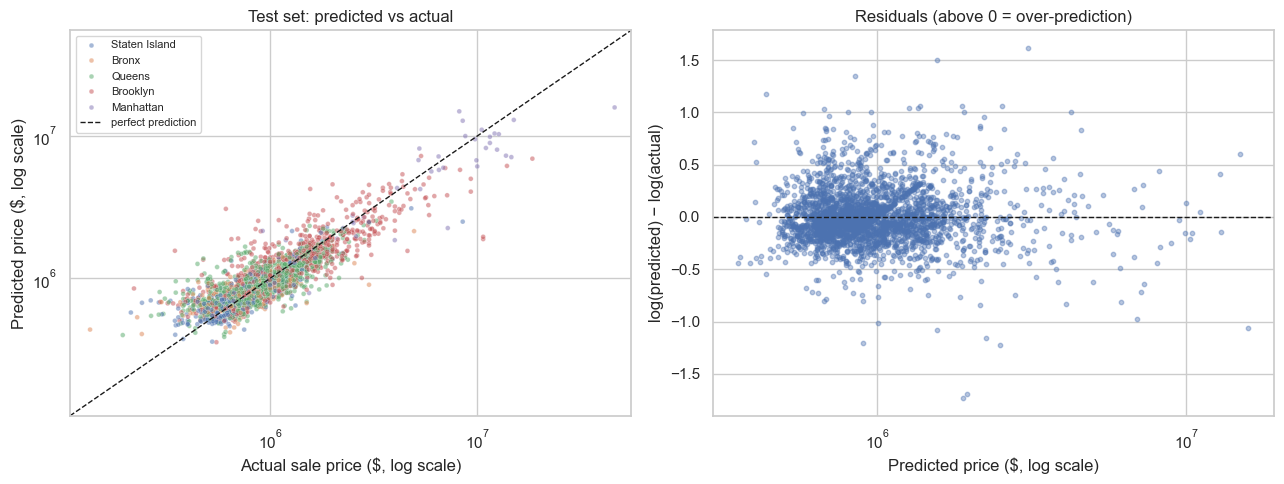

In [71]:
test_pred = pd.DataFrame({
    "actual": np.exp(y_test),
    "predicted": np.exp(final_model.predict(X_test)),
    "borough_name": X_test["borough_name"],
    "home_type": X_test["home_type"],
}, index=X_test.index)
test_pred["residual_log"] = np.log(test_pred["predicted"]) - np.log(test_pred["actual"])
test_pred["ape"] = (test_pred["predicted"] - test_pred["actual"]).abs() / test_pred["actual"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=test_pred, x="actual", y="predicted", hue="borough_name", hue_order=borough_order,
                s=12, alpha=0.5, ax=axes[0])
lims = [test_pred[["actual", "predicted"]].min().min() * 0.8, test_pred[["actual", "predicted"]].max().max() * 1.2]
axes[0].plot(lims, lims, "k--", lw=1, label="perfect prediction")
axes[0].set(xscale="log", yscale="log", xlim=lims, ylim=lims,
            xlabel="Actual sale price ($, log scale)", ylabel="Predicted price ($, log scale)",
            title="Test set: predicted vs actual")
axes[0].legend(fontsize=8)

axes[1].scatter(test_pred["predicted"], test_pred["residual_log"], s=10, alpha=0.4)
axes[1].axhline(0, color="k", ls="--", lw=1)
axes[1].set(xscale="log", xlabel="Predicted price ($, log scale)", ylabel="log(predicted) − log(actual)",
            title="Residuals (above 0 = over-prediction)")
plt.tight_layout()
plt.show()

**Observations**
- The points follow the diagonal closely over the whole range from about $300k to $10M, so the model has learned the price structure across all five boroughs.
- The residuals are **centred on zero** and have about the same spread at all price levels on the log scale. There is no funnel shape, which confirms that modelling the log price was a good choice: the model makes errors of similar *percentage* size for cheap and expensive homes.
- The pattern seen in the price bands below is visible here too. Cheap sales sit above the diagonal (over-predicted), and the most expensive Manhattan homes sit below it (under-predicted).

### 6.2 Where is the model accurate and where does it struggle?
Errors are broken down by **borough** and by **price band** (quintiles of the actual price). The **bias** column is the median of `predicted / actual − 1`: a positive value means the model tends to over-price homes in that group, a negative value means it under-prices them.

In [72]:
def error_summary(group):
    return pd.Series({
        "sales": len(group),
        "median actual": group["actual"].median(),
        "MAE ($)": (group["predicted"] - group["actual"]).abs().mean(),
        "MAPE": group["ape"].mean(),
        "Median APE": group["ape"].median(),
        "bias": np.median(group["predicted"] / group["actual"] - 1),
    })

fmt = {"sales": "{:,.0f}", "median actual": "${:,.0f}", "MAE ($)": "${:,.0f}",
       "MAPE": "{:.1%}", "Median APE": "{:.1%}", "bias": "{:+.1%}"}
by_borough = test_pred.groupby("borough_name").apply(error_summary, include_groups=False).loc[borough_order]
display(by_borough.style.format(fmt))

test_pred["price_band"] = pd.qcut(test_pred["actual"], 5)
by_band = test_pred.groupby("price_band", observed=True).apply(error_summary, include_groups=False)
by_band.index = [f"${b.left / 1e3:,.0f}k – ${b.right / 1e3:,.0f}k" for b in by_band.index]
display(by_band.style.format(fmt))

,sales,median actual,MAE ($),MAPE,Median APE,bias
borough_name,,,,,,
Staten Island,520,"$730,425","$125,609",15.9%,9.6%,-0.1%
Bronx,295,"$795,000","$159,807",20.2%,13.5%,-4.2%
Queens,"1,163","$930,000","$169,255",18.8%,12.8%,-3.5%
Brooklyn,785,"$1,158,000","$401,769",25.6%,17.2%,-2.0%
Manhattan,37,"$6,850,000","$2,736,438",29.7%,20.1%,-11.5%


,sales,median actual,MAE ($),MAPE,Median APE,bias
$135k – $665k,565,"$553,928","$167,413",35.3%,21.1%,+19.1%
$665k – $825k,577,"$750,000","$111,064",14.8%,9.4%,-2.5%
$825k – $995k,553,"$915,000","$132,693",14.5%,10.2%,-1.7%
"$995k – $1,380k",550,"$1,170,000","$186,218",15.9%,13.0%,-7.8%
"$1,380k – $46,000k",555,"$1,800,000","$705,350",21.7%,18.4%,-13.5%


In [73]:
# Same price-band breakdown for the Random Forest, to check the dollar-RMSE difference seen in Section 5
rf_ape = (np.exp(final_models["Random Forest"].predict(X_test)) - test_pred["actual"]).abs() / test_pred["actual"]
band_compare = pd.DataFrame({
    f"{FINAL_MODEL_NAME} MAPE": test_pred.groupby("price_band", observed=True)["ape"].mean().values,
    "Random Forest MAPE": rf_ape.groupby(test_pred["price_band"], observed=True).mean().values,
}, index=by_band.index)
band_compare.style.format("{:.1%}")

,Gradient Boosting MAPE,Random Forest MAPE
$135k – $665k,35.3%,35.8%
$665k – $825k,14.8%,14.8%
$825k – $995k,14.5%,14.4%
"$995k – $1,380k",15.9%,15.8%
"$1,380k – $46,000k",21.7%,21.0%


In [74]:
# The 10 largest percentage errors: what kind of sales are they?
worst = test_pred.nlargest(10, "ape").join(X_test[["neighborhood", "building_class_at_time_of_sale", "log_gross_sqft"]])
worst["gross_sqft"] = np.exp(worst["log_gross_sqft"]).round()
worst[["borough_name", "neighborhood", "home_type", "building_class_at_time_of_sale", "gross_sqft",
       "actual", "predicted", "ape"]].style.format(
    {"actual": "${:,.0f}", "predicted": "${:,.0f}", "ape": "{:.0%}", "gross_sqft": "{:,.0f}"})

,borough_name,neighborhood,home_type,building_class_at_time_of_sale,gross_sqft,actual,predicted,ape
41547,Brooklyn,GREENPOINT,1-family,A9,"2,500","$610,950","$3,075,667",403%
30530,Brooklyn,BOROUGH PARK,1-family,A9,"1,392","$346,750","$1,560,814",350%
40859,Brooklyn,GRAVESEND,1-family,A5,"1,096","$220,000","$847,961",285%
25329,Bronx,THROGS NECK,1-family,A8,nan,"$135,000","$435,939",223%
35404,Brooklyn,CROWN HEIGHTS,2-family,B3,"2,576","$650,000","$1,884,225",190%
45434,Brooklyn,PARK SLOPE,1-family,A9,992,"$875,000","$2,532,427",189%
66160,Queens,JAMAICA ESTATES,1-family,A1,"1,740","$475,868","$1,377,092",189%
41206,Brooklyn,GRAVESEND,3-family,C0,"2,704","$475,000","$1,350,377",184%
61400,Queens,FOREST HILLS,1-family,A5,"1,740","$445,649","$1,262,369",183%
78216,Staten Island,CASTLETON CORNERS,1-family,A0,"1,136","$240,445","$672,590",180%


**Observations**
- **The model is most accurate for typical homes.** In the middle price bands ($665k–$995k) the median error is about **10%**, which is useful for a first valuation.
- **It over-prices the cheapest fifth of sales by about 19%.** Many of these are probably not true market sales (family or distress sales, or homes in poor condition) that survived the cleaning in 4a. The model correctly predicts what a home *like this* usually sells for, but the recorded price is lower. The largest percentage errors above fit this: ordinary homes in Greenpoint, Park Slope or Forest Hills sold at a fraction of what similar homes sell for.
- **It under-prices the most expensive homes by about 13%.** This is the usual "pull towards the average" of models trained on few extreme examples. Very expensive homes are rare in the training data, so the model is cautious with them.
- **By borough:** Staten Island is the easiest (10% median error, its housing is the most uniform). Manhattan is the hardest (20%, only 37 test sales, and it is under-priced by about 11%).
- **Random Forest vs Gradient Boosting:** the error per price band is almost identical for the two models, including the most expensive band. The difference in dollar RMSE in Section 5 therefore came from a few individual sales rather than from a systematic weakness of either model.

### 6.3 Which features drive the predictions?
**Permutation importance** is measured on the test set: each original feature is randomly shuffled, one at a time, and the increase in RMSE shows how much the model relies on it. Because the shuffling is done on the raw columns *before* the pipeline, a feature such as borough is measured as a whole rather than as separate one-hot columns. It is repeated 10 times to show how stable the result is.

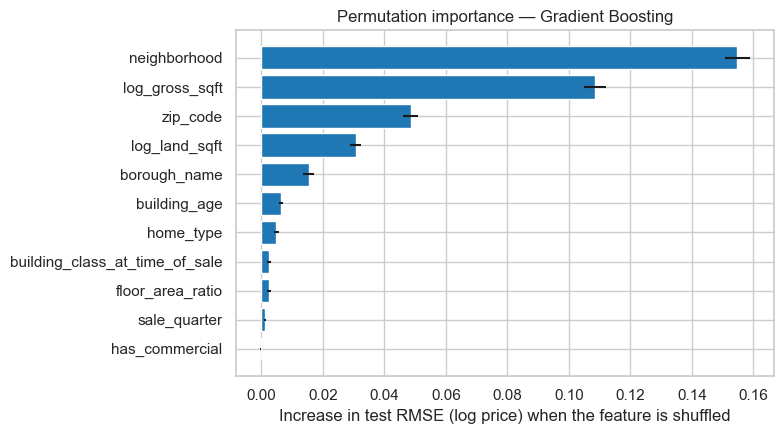

,mean,std
neighborhood,0.1547,0.0040
log_gross_sqft,0.1085,0.0035
zip_code,0.0486,0.0024
log_land_sqft,0.0307,0.0018
borough_name,0.0154,0.0018
building_age,0.0064,0.0007
home_type,0.0049,0.0007
building_class_at_time_of_sale,0.0025,0.0007
floor_area_ratio,0.0024,0.0007
sale_quarter,0.0013,0.0003


In [75]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(final_model, X_test, y_test, scoring="neg_root_mean_squared_error",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std},
                          index=X_test.columns).sort_values("mean")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(importance.index, importance["mean"], xerr=importance["std"], color="tab:blue")
ax.set_xlabel("Increase in test RMSE (log price) when the feature is shuffled")
ax.set_title(f"Permutation importance — {FINAL_MODEL_NAME}")
plt.tight_layout()
plt.show()
importance.sort_values("mean", ascending=False).style.format("{:.4f}")

**Observations**
- **Location dominates.** Shuffling the neighbourhood increases the error by 0.15, more than any other feature, and ZIP code is third (0.05). This confirms the main EDA finding: *where* a home is matters more than anything else.
- The two location columns **share information**. When one of them is shuffled the model can still partly locate the home from the other, so each one looks less important on its own than location really is. The ZIP check in 4d measured their combined value directly.
- **Building size comes second**, and land size fourth. Together with location these explain almost all of what the model has learned.
- **Borough adds a little on top of neighbourhood**, mainly for small neighbourhoods whose own encoding is unreliable (see 4d).
- **Floor area ratio has low importance** even though its correlation with price was 0.43 in 4b. It is calculated from the two size columns, so once the model has those it adds little new information. Permutation importance measures what a feature adds *given the others*, while correlation looks at each feature alone.
- **Sale quarter and the commercial-unit flag contribute almost nothing.** Prices were stable during 2025 (Section 3.9), and very few 1–3 family homes have commercial units.

### 6.4 Saving the final model
The complete pipeline (preprocessing + model) is saved, so the Streamlit app can take raw inputs such as borough, neighbourhood and size and apply exactly the same preparation before predicting.

In [76]:
import joblib

MODEL_DIR = Path("../models")
joblib.dump(final_model, MODEL_DIR / "final_model.joblib", compress=3)
print(f"Saved: {MODEL_DIR / 'final_model.joblib'} "
      f"({(MODEL_DIR / 'final_model.joblib').stat().st_size / 1e6:.1f} MB)")

Saved: ../models/final_model.joblib (1.5 MB)


### 6.5 Exporting data and results for the Streamlit app
The app does not re-run this notebook. It reads the cleaned dataset and the evaluation results saved here, so that the dashboard and the model-performance page show exactly the numbers reported above.

In [77]:
PROCESSED_DIR = Path("../data/processed")
RESULTS_DIR = MODEL_DIR / "results"
PROCESSED_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

# Cleaned homes, with the split each sale belongs to
split = pd.Series("train", index=df_feat.index)
split[X_val.index] = "validation"
split[X_test.index] = "test"
app_cols = ["borough_name", "neighborhood", "zip_code", "home_type", "building_class_at_time_of_sale",
            "gross_square_feet", "land_square_feet", "year_built", "commercial_units",
            "sale_price", "sale_date", "building_age", "floor_area_ratio", "has_commercial", "sale_quarter"]
df_feat[app_cols].assign(split=split).to_csv(PROCESSED_DIR / "homes_2025_clean.csv", index_label="row_id")

# Model comparison: CV, validation and test scores
comparison = (val_results.add_prefix("val ")
              .join(test_results.drop(columns="MSE (log)").add_prefix("test "))
              .rename(columns={"val CV RMSE (log)": "CV RMSE (log)", "val Train RMSE (log)": "Train RMSE (log)"}))
comparison["best params"] = [str({k.replace("model__", ""): v for k, v in tuned[n].best_params_.items()})
                             for n in comparison.index]
comparison.to_csv(RESULTS_DIR / "model_comparison.csv", index_label="model")

test_pred.drop(columns="price_band").to_csv(RESULTS_DIR / "test_predictions.csv", index_label="row_id")
importance.to_csv(RESULTS_DIR / "permutation_importance.csv", index_label="feature")
pd.DataFrame(cleaning_log, columns=["step", "rows"]).to_csv(RESULTS_DIR / "cleaning_log.csv", index=False)

for f in sorted([*PROCESSED_DIR.glob("*.csv"), *RESULTS_DIR.glob("*.csv")]):
    print(f"{f}  ({f.stat().st_size / 1e3:,.0f} kB)")

../data/processed/homes_2025_clean.csv  (2,306 kB)
../models/results/cleaning_log.csv  (0 kB)
../models/results/model_comparison.csv  (2 kB)
../models/results/permutation_importance.csv  (1 kB)
../models/results/test_predictions.csv  (279 kB)


### 6.6 Evaluation summary

| | Final model on the **test set** |
|---|---|
| Model | Histogram Gradient Boosting (learning rate 0.01, 1,000 trees, 31 leaves, min. 20 homes per leaf), trained on 15,864 homes |
| Typical error | **Median 13.6%**, about $120k on a typical $900k home |
| Average error | MAE $259k · MAPE 20.5% |
| Log scale | RMSE 0.270 · MAE 0.192 · **R² 0.75** |
| vs linear baseline | Median error 14.1% → 13.6%; RMSE (log) 0.276 → 0.270 |
| Most accurate for | Typical homes ($665k–$995k): about 10% median error. Staten Island: 10%. |
| Weakest for | The cheapest fifth of sales (over-priced by about 19%, many probably non-market) and Manhattan / luxury homes (under-priced, few training examples) |
| Main drivers | Neighbourhood, building size, ZIP code, then land size and borough |

**Limitations**
- The data contains only what is in the public sales record. Condition, renovation, views and the exact location below ZIP-code level are not available, and they probably explain most of the remaining ~14% error.
- Manhattan has very few 1–3 family sales (37 in the test set), so predictions there are much less reliable.
- The model learns 2025 prices. It would need re-training on newer sales to stay accurate as the market moves.